# 1. Saúde da Mulher na África Subsaariana

**Contracepção, pré-natal e desigualdades sociais · TZ1 / DCC011**

Quanto das diferenças rurais e urbanas se relaciona à riqueza e à escolaridade?


# 2. Membros

Henrique Lima Gusmão (2025014508) 
Felipe Pires Franco () 
Izabella Galdino Correia () 
Alice Lina Oliveira da Silva () 

# 3. Dados e processamento

**Fonte:** microdados Stata do DHS · **37 países** · pesquisas de períodos diferentes.

### 3.1 Obtenção e reprodução

1. Solicitar acesso no [DHS Program](https://dhsprogram.com/data/Access-Instructions.cfm).
2. Clonar o repositório com Git LFS e instalar `requirements.txt`, conforme o README.
3. Baixar/extrair IR, BR, HR, PR e KR; executar os scripts de preparação abaixo e este notebook, na ordem, na raiz do projeto.

```bash
python database_python/baixar_datasets.py --urls-file catalogo_datasets.csv --recode IR,BR,HR,PR,KR --extract --output-dir dados/completo
python database_python/preparar_dados_projeto.py --source dados/completo/extraidos --output dados/relevantes
python database_python/carregar_sqlite.py
```

O [manifesto contraceptivo](docs/manifesto_contracepcao.json) identifica os dez IR suplementares: país, arquivo DT.zip/DTA, pesquisa, período e URL. Baixá-los com acesso DHS autorizado e extrair em `dados/completo/extraidos` ou `dados/extraidos`. A carga procura os nomes exatos, sem transferir respostas entre pesquisas.

### 3.2 Construção bottom-up

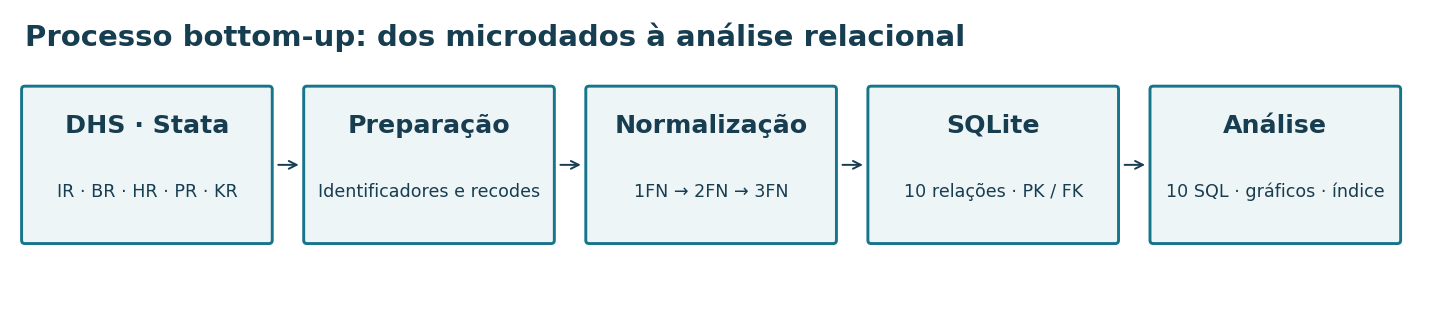

**1FN:** valores escalares; `v304_01…09` vira linhas Mulher–Método. **2FN:** nível de conhecimento depende do par completo. **3FN:** país, levantamento, contexto habitacional e catálogo de métodos ficam em relações próprias.

<details><summary>Dependências funcionais e integração</summary>

- País → nome; levantamento → país, fase.
- Levantamento + cluster + domicílio → contexto habitacional.
- Domicílio + linha → mulher ou morador; mulher → entrevista selecionada.
- Mulher + índice → nascimento; nascimento → acompanhamento KR.
- Método → nome, classe; mulher + método → nível de conhecimento.

Chaves naturais evitam diferenças de espaços em `caseid`; PK, FK, UNIQUE e CHECK validam a carga. Há 5.189 domicílios `IR_sem_HR` e 53.333 nascimentos `KR_sem_BR`; ausência permanece NULL. Anos antigos são reconstruídos por CMC: 1900 + piso((CMC−1)/12). A origem é lida sem alterações; o banco derivado só é substituído após validação.

</details>

### 3.3 Recortes e leitura dos indicadores

**Núcleo:** 407.600 entrevistas. **Suplemento:** 176.404 observações independentes. **Contracepção:** uma pesquisa por país, 510.884 entrevistas antes dos filtros. Pré-natal e habitação usam o núcleo.

**Conhecer ≠ usar.** `v304` mede conhecimento; `v312` mede uso atual de qualquer método. Pré-natal ≥4 é um limiar histórico descritivo. Ausência não é zero; pesos `v005/1.000.000` são usados dentro de cada levantamento.

<details><summary>Semântica, fontes e limites</summary>

BR representa nascidos vivos, e `v212` é idade no primeiro nascimento. O M:N conserva nove métodos de semântica estável, nível 0–7; código 7 identifica método fora da tabela de contracepção e é considerado positivo pela rotina DHS. Isso pode saturar o indicador agregado; a Q8 inclui sensibilidade sem esse código. Códigos ausentes não viram desconhecimento. `v307` não é intercambiável entre fases. Uso atual: 0 = nenhum, 1–19 = algum método. Pré-natal: códigos 0–90 válidos, NULL/98/99 excluídos. `m3b` varia por país e não é usado como assistência qualificada continental.

As pesquisas não são simultâneas: Sudão, 1989–1990; República Centro-Africana, 1994–1995. Somar pesos nacionais não estima a população continental. As comparações são descritivas, sem causalidade ou intervalos de confiança sem desenho amostral.

Fontes: [rotina DHS de conhecimento](https://github.com/DHSProgram/DHS-Indicators-Stata/blob/master/Chap07_FP/FP_KNOW.do), [recode DHS7](https://dhsprogram.com/pubs/pdf/DHSG4/Recode7_DHS_10Sep2018_DHSG4.pdf), [amostragem DHS](https://dhsprogram.com/pubs/pdf/DHSM4/DHS6_Sampling_Manual_Sept2012_DHSM4.pdf).

</details>

### 3.4 Carga e cobertura

Código recolhido; resultados e verificações abaixo. A execução reconstrói `saude_mulher_normalizado.db` e valida a origem, contagens e integridade referencial.


In [1]:
from pathlib import Path
import os
import sqlite3


def construir_banco(origem, destino, suplementos=()):
    """Transforma o núcleo DHS em relações com PK/FK, sem alterar a origem."""
    origem, destino = Path(origem).resolve(), Path(destino).resolve()
    if origem == destino:
        raise ValueError('Origem e destino devem ser diferentes.')
    temporario = destino.with_suffix('.tmp.db')
    if temporario.exists():
        temporario.unlink()
    c = sqlite3.connect(temporario, uri=True)
    c.execute('PRAGMA foreign_keys=ON')
    c.execute('ATTACH DATABASE ? AS fonte', (origem.as_uri()+'?mode=ro',))
    dom = "levantamento_id || '|' || CAST(v001 AS INTEGER) || '|' || CAST(v002 AS INTEGER)"
    mulher = dom + " || '|' || CAST(v003 AS INTEGER)"
    nasc = mulher + " || '|' || CAST(bidx AS INTEGER)"
    try:
        c.executescript('''
        CREATE TABLE Pais(codigo TEXT PRIMARY KEY, nome TEXT NOT NULL UNIQUE);
        CREATE TABLE Levantamento(id TEXT PRIMARY KEY, pais_codigo TEXT NOT NULL REFERENCES Pais(codigo), fase TEXT NOT NULL, UNIQUE(pais_codigo,fase));
        CREATE TABLE Domicilio(
          id TEXT PRIMARY KEY, levantamento_id TEXT NOT NULL REFERENCES Levantamento(id),
          cluster INTEGER NOT NULL, numero INTEGER NOT NULL, regiao INTEGER,
          residencia INTEGER CHECK(residencia IN(1,2)), riqueza INTEGER CHECK(riqueza BETWEEN 1 AND 5),
          eletricidade INTEGER CHECK(eletricidade IN(0,1)), fonte_agua INTEGER, membros INTEGER,
          origem TEXT NOT NULL CHECK(origem IN('HR','IR_sem_HR','IR_completo')),
          UNIQUE(levantamento_id,cluster,numero));
        CREATE TABLE Mulher(
          id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,
          idade INTEGER, escolaridade INTEGER CHECK(escolaridade BETWEEN 0 AND 3),
          filhos_nascidos_vivos INTEGER, idade_primeiro_nascimento INTEGER,
          UNIQUE(domicilio_id,linha));
        CREATE TABLE Entrevista(
          mulher_id TEXT PRIMARY KEY REFERENCES Mulher(id), ano INTEGER, mes INTEGER,
          data_cmc INTEGER, peso REAL CHECK(peso>0), usa_metodo INTEGER CHECK(usa_metodo IN(0,1)),
          coorte TEXT NOT NULL CHECK(coorte IN('nucleo_e_contracepcao','nucleo_exclusivo','contracepcao')));
        CREATE TABLE Nascimento(
          id TEXT PRIMARY KEY, mulher_id TEXT NOT NULL REFERENCES Mulher(id), indice INTEGER NOT NULL CHECK(indice>=1),
          ano INTEGER, mes INTEGER, data_cmc INTEGER, sexo INTEGER CHECK(sexo IN(1,2)), vivo INTEGER CHECK(vivo IN(0,1)),
          consultas_prenatal_codigo INTEGER, local_parto_codigo INTEGER, cesarea_codigo INTEGER,
          assistencia_medico_codigo INTEGER, assistencia_m3b_codigo INTEGER,
          origem TEXT NOT NULL CHECK(origem IN('BR','KR_sem_BR')), UNIQUE(mulher_id,indice));
        CREATE TABLE Crianca(
          nascimento_id TEXT PRIMARY KEY REFERENCES Nascimento(id), idade_anos INTEGER,
          diarreia_codigo INTEGER, cartao_vacina_codigo INTEGER);
        CREATE TABLE Morador(
          id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,
          sexo INTEGER, idade INTEGER, escolaridade_codigo INTEGER, relacao_chefe_codigo INTEGER,
          UNIQUE(domicilio_id,linha));
        CREATE TABLE Metodo(
          id INTEGER PRIMARY KEY, nome TEXT NOT NULL UNIQUE, classe TEXT NOT NULL CHECK(classe IN('Moderno','Tradicional')));
        CREATE TABLE Conhecimento_Metodo(
          mulher_id TEXT NOT NULL REFERENCES Mulher(id), metodo_id INTEGER NOT NULL REFERENCES Metodo(id),
          nivel INTEGER NOT NULL CHECK(nivel BETWEEN 0 AND 7), PRIMARY KEY(mulher_id,metodo_id)) WITHOUT ROWID;
        INSERT INTO Pais SELECT pais_codigo,nome_pais FROM fonte.Pais;
        INSERT INTO Levantamento SELECT levantamento_id,pais_codigo,fase FROM fonte.Levantamento;
        INSERT INTO Domicilio
        SELECT levantamento_id||'|'||CAST(hv001 AS INTEGER)||'|'||CAST(hv002 AS INTEGER),
               levantamento_id,hv001,hv002,hv024,
               CASE WHEN hv025 IN(1,2) THEN hv025 END,
               CASE WHEN hv270 BETWEEN 1 AND 5 THEN hv270 END,
               CASE WHEN hv206 IN(0,1) THEN hv206 END,hv201,hv009,'HR'
        FROM fonte.Domicilio;
        ''')
        c.execute(f'''INSERT OR IGNORE INTO Domicilio
        SELECT {dom},levantamento_id,v001,v002,MAX(v024),
               MAX(CASE WHEN v025 IN(1,2) THEN v025 END),
               MAX(CASE WHEN v190 BETWEEN 1 AND 5 THEN v190 END),
               NULL,NULL,NULL,'IR_sem_HR'
        FROM fonte.Mulher GROUP BY levantamento_id,v001,v002''')
        c.execute(f'''INSERT INTO Mulher
        SELECT {mulher},{dom},v003,v012,
               CASE WHEN v106 BETWEEN 0 AND 3 THEN v106 END,v201,
               CASE WHEN v212 BETWEEN 10 AND 49 THEN v212 END
        FROM fonte.Mulher''')
        c.execute(f'''INSERT INTO Entrevista
        SELECT {mulher},CASE WHEN v007 BETWEEN 0 AND 99 THEN
               CASE WHEN v008>0 THEN 1900+CAST((v008-1)/12 AS INTEGER) END ELSE v007 END,v006,v008,
               CASE WHEN v005>0 THEN v005/1000000.0 END,
               CASE WHEN v312=0 THEN 0 WHEN v312 BETWEEN 1 AND 19 THEN 1 END,'nucleo_e_contracepcao'
        FROM fonte.Mulher''')
        for tabela, origem_registro in [('Nascimento','BR'),('Crianca','KR_sem_BR')]:
            assistencia='m3a,m3b' if tabela=='Nascimento' else 'NULL,NULL'
            c.execute(f'''INSERT OR IGNORE INTO Nascimento
            SELECT {nasc},{mulher},bidx,CASE WHEN b2 BETWEEN 0 AND 99 THEN
                   CASE WHEN b3>0 THEN 1900+CAST((b3-1)/12 AS INTEGER) END ELSE b2 END,b1,b3,
                   CASE WHEN b4 IN(1,2) THEN b4 END,
                   CASE WHEN b5 IN(0,1) THEN b5 END,
                   m14,m15,m17,{assistencia},?
            FROM fonte.{tabela}''',(origem_registro,))
        c.execute(f'''INSERT INTO Crianca
        SELECT {nasc},b8,h11,h1 FROM fonte.Crianca''')
        c.execute('''INSERT INTO Morador
        SELECT levantamento_id||'|'||CAST(hv001 AS INTEGER)||'|'||CAST(hv002 AS INTEGER)||'|'||CAST(hvidx AS INTEGER),
               levantamento_id||'|'||CAST(hv001 AS INTEGER)||'|'||CAST(hv002 AS INTEGER),
               hvidx,hv104,hv105,hv106,hv101 FROM fonte.Morador''')
        c.executemany('INSERT INTO Metodo VALUES(?,?,?)',[
            (1,'Pílula','Moderno'),(2,'DIU','Moderno'),(3,'Injetáveis','Moderno'),
            (4,'Diafragma / espuma / gel','Moderno'),(5,'Preservativo masculino','Moderno'),
            (6,'Esterilização feminina','Moderno'),(7,'Esterilização masculina','Moderno'),
            (8,'Abstinência periódica','Tradicional'),(9,'Coito interrompido','Tradicional')])
        for metodo in range(1,10):
            coluna=f'v304_{metodo:02d}'
            c.execute(f'''INSERT INTO Conhecimento_Metodo
            SELECT {mulher},?,{coluna} FROM fonte.Mulher
            WHERE {coluna} BETWEEN 0 AND 7''',(metodo,))
        # Pesquisas completas suplementares: entrevistas independentes, nunca imputadas
        # nas mulheres da pesquisa original. Uma pesquisa por país no tema contracepção.
        if len({s['pais_codigo'] for s in suplementos}) != len(suplementos):
            raise ValueError('Selecionar somente um suplemento por país.')
        for s in suplementos:
            import pyreadstat
            codigo, fase = s['pais_codigo'], s['fase']
            lev = codigo+'_'+fase
            colunas = ['v001','v002','v003','v024','v025','v190','v012','v106','v201','v212',
                       'v006','v007','v008','v005','v312']+[f'v304_{i:02d}' for i in range(1,10)]
            df, _ = pyreadstat.read_dta(str(s['caminho_origem']), usecols=colunas, apply_value_formats=False)
            if len(df)!=s['N'] or set(colunas)-set(df.columns):
                raise ValueError(f'Arquivo suplementar incompatível: {lev}')
            if df[['v001','v002','v003']].isna().any().any():
                raise ValueError(f'Chaves ausentes: {lev}')
            df['levantamento_id']=lev
            # pandas converte NaN em NULL; a tabela intermediária é removida após a carga.
            df.to_sql('ir_suplementar',c,index=False,if_exists='replace')
            c.execute('INSERT OR IGNORE INTO Levantamento VALUES(?,?,?)',(lev,codigo,fase))
            c.execute("UPDATE Entrevista SET coorte='nucleo_exclusivo' WHERE substr(mulher_id,1,2)=?",(codigo,))
            c.execute(f'''INSERT INTO Domicilio SELECT {dom},levantamento_id,v001,v002,MAX(v024),
                       MAX(CASE WHEN v025 IN(1,2) THEN v025 END),
                       MAX(CASE WHEN v190 BETWEEN 1 AND 5 THEN v190 END),
                       NULL,NULL,NULL,'IR_completo'
                       FROM ir_suplementar GROUP BY levantamento_id,v001,v002''')
            c.execute(f'''INSERT INTO Mulher SELECT {mulher},{dom},v003,v012,
                       CASE WHEN v106 BETWEEN 0 AND 3 THEN v106 END,v201,
                       CASE WHEN v212 BETWEEN 10 AND 49 THEN v212 END FROM ir_suplementar''')
            c.execute(f'''INSERT INTO Entrevista SELECT {mulher},CASE WHEN v007 BETWEEN 0 AND 99 THEN
                       CASE WHEN v008>0 THEN 1900+CAST((v008-1)/12 AS INTEGER) END ELSE v007 END,v006,v008,
                       CASE WHEN v005>0 THEN v005/1000000.0 END,
                       CASE WHEN v312=0 THEN 0 WHEN v312 BETWEEN 1 AND 19 THEN 1 END,
                       'contracepcao' FROM ir_suplementar''')
            for metodo in range(1,10):
                coluna=f'v304_{metodo:02d}'
                c.execute(f'''INSERT INTO Conhecimento_Metodo SELECT {mulher},?,{coluna}
                           FROM ir_suplementar WHERE {coluna} BETWEEN 0 AND 7''',(metodo,))
            c.execute('DROP TABLE ir_suplementar')
        # Índices de FK: integridade e navegação, além das PK/UNIQUE já existentes.
        c.executescript('''
        CREATE INDEX idx_dom_levantamento ON Domicilio(levantamento_id);
        CREATE INDEX idx_lev_pais ON Levantamento(pais_codigo);
        ''')
        falhas=c.execute('PRAGMA foreign_key_check').fetchall()
        if falhas: raise ValueError(f'Integridade referencial inválida: {falhas[:5]}')
        for tabela in ['Mulher','Crianca','Morador']:
            campo='COUNT(*)'
            bruto=c.execute(f'SELECT {campo} FROM fonte.{tabela}').fetchone()[0]
            final=c.execute(f'SELECT {campo} FROM {tabela}').fetchone()[0]
            if tabela=='Mulher':
                final=c.execute("SELECT COUNT(*) FROM Entrevista WHERE coorte!='contracepcao'").fetchone()[0]
            if bruto != final: raise ValueError(f'Perda de registros em {tabela}: {bruto} -> {final}')
        br=c.execute('SELECT COUNT(*) FROM fonte.Nascimento').fetchone()[0]
        if c.execute("SELECT COUNT(*) FROM Nascimento WHERE origem='BR'").fetchone()[0] != br:
            raise ValueError('Perda ou duplicidade de nascimentos BR.')
        if c.execute('PRAGMA integrity_check').fetchone()[0]!='ok':
            raise ValueError('Banco não passou na verificação de integridade.')
        c.commit()
    except Exception:
        c.close()
        temporario.unlink(missing_ok=True)
        raise
    c.close()
    os.replace(temporario,destino)
    return destino


pais_codigo,arquivo_origem,fase,anos,N,surv_id
CM,CMIR71FL.DTA,71,"[2018, 2019]",14677,511
GH,GHIR8CFL.DTA,8C,"[2022, 2023]",15014,598
GN,GNIR71FL.DTA,71,"[2018, 2018]",10874,539
KE,KEIR8CFL.DTA,8C,"[2022, 2022]",32156,566
LB,LBIR7AFL.DTA,7A,"[2019, 2020]",8065,537
ML,MLIR8AFL.dta,8A,"[2023, 2024]",20354,613
NG,NGIR8BFL.dta,8B,"[2023, 2024]",39050,609
NI,NIIR61FL.DTA,61,"[2012, 2012]",11160,407
SL,SLIR7AFL.DTA,7A,"[2019, 2019]",15574,545
TG,TGIR61FL.DTA,61,"[2013, 2014]",9480,328


Carga normalizada concluída em 71.68 s.


relacao,registros
Pais,37
Levantamento,114
Domicilio,512027
Mulher,584004
Entrevista,584004
Nascimento,930745
Crianca,282641
Morador,1884683
Metodo,9
Conhecimento_Metodo,4437906


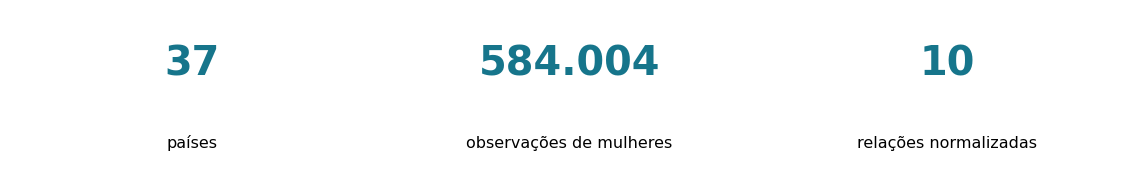

PK/FK, integridade e contagens de origem validadas; hash da origem preservado.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from time import perf_counter
from statistics import median
import hashlib

raiz = Path.cwd()
origem = raiz / "saude_mulher_dhs.db"
destino = Path(os.environ.get("DHS_REPORT_DB", raiz / "saude_mulher_normalizado.db"))
def sha256(arquivo):
    h=hashlib.sha256()
    with arquivo.open('rb') as f:
        for bloco in iter(lambda: f.read(4*1024*1024), b''): h.update(bloco)
    return h.hexdigest()
hash_origem = sha256(origem)
import json
manifesto=json.loads((raiz/'docs/manifesto_contracepcao.json').read_text(encoding='utf-8'))
pastas=[raiz/'dados/completo/extraidos',raiz/'dados/extraidos',
        raiz.parent/'_dados_descartados_saude_mulher/completo/extraidos']
suplementos=[]
for item in manifesto:
    encontrados=[a for pasta in pastas if pasta.exists() for a in pasta.rglob(item['arquivo_origem'])]
    if not encontrados:
        raise FileNotFoundError(f"Obter/extrair o arquivo DHS do manifesto: {item['arquivo_origem']}")
    suplementos.append(dict(item,caminho_origem=str(encontrados[0])))
display(HTML('<details><summary>Manifesto dos dez suplementos</summary>'+pd.DataFrame(manifesto)[['pais_codigo','arquivo_origem','fase','anos','N','surv_id']].to_html(index=False)+'</details>'))
t0=perf_counter()
construir_banco(origem,destino,suplementos)
print(f"Carga normalizada concluída em {perf_counter()-t0:.2f} s.")
assert sha256(origem)==hash_origem, "A origem deve permanecer intacta."
conn=sqlite3.connect(destino)
conn.execute('PRAGMA foreign_keys=ON')

# Apresentação: SQL visível, detalhes sob demanda e resultados em gráficos.
import html
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,
                     'axes.spines.right':False,'figure.dpi':115})
AZUL, LARANJA = '#16758b', '#bc651b'

def detalhes(tabela, titulo='Resultado completo'):
    display(HTML('<details><summary>'+html.escape(titulo)+f' · {len(tabela):,} linhas</summary>'
                 +tabela.to_html(index=False,escape=True)+'</details>'))

def consulta(sql, amostra=False):
    tabela=pd.read_sql_query(sql,conn)
    if amostra:
        detalhes(tabela.groupby('pais_codigo').head(1), 'Exemplo de cada país presente')
        # Evitar incorporar dezenas de milhares de microdados na saída do relatório.
        detalhes(tabela.groupby('pais_codigo').size().rename('registros').reset_index(), 'Contagens da seleção por país')
        display(Markdown(f'**Resultado:** {len(tabela):,} registros. Dados integrais em `r1`/`r2` após execução.'))
    else:
        detalhes(tabela)
    return tabela

def mostrar(fig):
    fig.tight_layout(); display(fig); plt.close(fig)

def barras(valores, titulo, unidade, percentual=False):
    valores=valores.dropna().sort_values()
    fig,ax=plt.subplots(figsize=(10,max(3,len(valores)*.23)))
    ax.barh(valores.index.astype(str),valores.values,color=AZUL)
    ax.set(title=titulo,xlabel=unidade,xlim=(0,100) if percentual else (0,None))
    ax.grid(axis='x',alpha=.15); mostrar(fig)

def mapa(tabela, titulo, unidade='%'):
    fig,ax=plt.subplots(figsize=(9,max(4,len(tabela)*.23)))
    cmap=plt.get_cmap('cividis').copy(); cmap.set_bad('#dddddd')
    im=ax.imshow(tabela.to_numpy(dtype=float),aspect='auto',cmap=cmap,vmin=0,vmax=100)
    ax.set(yticks=np.arange(len(tabela)),yticklabels=tabela.index,
           xticks=np.arange(len(tabela.columns)),xticklabels=tabela.columns,title=titulo)
    ax.tick_params(axis='x',labelrotation=25)
    for y,row in enumerate(tabela.to_numpy(dtype=float)):
        for x,v in enumerate(row):
            ax.text(x,y,'—' if np.isnan(v) else f'{v:.0f}',ha='center',va='center',fontsize=7,
                    color='white' if not np.isnan(v) and v<45 else 'black')
    fig.colorbar(im,ax=ax,label=unidade); mostrar(fig)

def pares(tabela, esquerda, direita, titulo, unidade='%'):
    tabela=tabela[[esquerda,direita]].dropna().sort_values(direita)
    fig,ax=plt.subplots(figsize=(10,max(4,len(tabela)*.23)))
    y=np.arange(len(tabela)); ax.hlines(y,tabela[esquerda],tabela[direita],color='#a0b0bc')
    ax.scatter(tabela[esquerda],y,label=esquerda,color=AZUL,marker='o')
    ax.scatter(tabela[direita],y,label=direita,color=LARANJA,marker='s')
    ax.set(yticks=y,yticklabels=tabela.index,title=titulo,xlabel=unidade,xlim=(0,100))
    ax.legend(loc='best'); ax.grid(axis='x',alpha=.15); mostrar(fig)

nomes=dict(conn.execute('SELECT codigo,nome FROM Pais').fetchall())
def nomear(df):
    return df.rename(index=nomes).sort_index()

resumo=pd.DataFrame([(t,conn.execute(f'SELECT COUNT(*) FROM {t}').fetchone()[0])
                    for t in ['Pais','Levantamento','Domicilio','Mulher','Entrevista','Nascimento','Crianca','Morador','Metodo','Conhecimento_Metodo']],
                   columns=['relacao','registros'])
detalhes(resumo,'Contagens e relações do banco')
fig,axs=plt.subplots(1,3,figsize=(10,1.7))
for ax,valor,rotulo in zip(axs,['37','584.004','10'],['países','observações de mulheres','relações normalizadas']):
    ax.axis('off'); ax.text(.5,.6,valor,ha='center',fontsize=25,color=AZUL,weight='bold'); ax.text(.5,.15,rotulo,ha='center',fontsize=10)
mostrar(fig)
assert conn.execute('PRAGMA foreign_key_check').fetchall()==[]
assert conn.execute('SELECT COUNT(*) FROM Mulher').fetchone()[0]==584004
assert conn.execute("SELECT COUNT(*) FROM Entrevista WHERE coorte!='contracepcao'").fetchone()[0]==407600
assert conn.execute("SELECT COUNT(*) FROM Entrevista WHERE coorte!='nucleo_exclusivo'").fetchone()[0]==510884
assert conn.execute('SELECT COUNT(*) FROM Crianca').fetchone()[0]==282641
assert conn.execute('SELECT COUNT(*) FROM Morador').fetchone()[0]==1884683
assert conn.execute("SELECT COUNT(*) FROM Nascimento WHERE origem='BR'").fetchone()[0]==877412
assert conn.execute("SELECT COUNT(*) FROM Nascimento WHERE origem='KR_sem_BR'").fetchone()[0]==53333
assert conn.execute("SELECT COUNT(*) FROM Domicilio WHERE origem='IR_sem_HR'").fetchone()[0]==5189
print('PK/FK, integridade e contagens de origem validadas; hash da origem preservado.')


In [3]:
cobertura=consulta("""
SELECT p.codigo,p.nome,l.fase,e.coorte, MIN(e.ano) AS ano_min,MAX(e.ano) AS ano_max,
       COUNT(*) AS mulheres,
       SUM(e.usa_metodo IS NOT NULL) AS resposta_contraceptiva,
       SUM(d.riqueza IS NOT NULL) AS riqueza_disponivel,
       SUM(d.origem='HR') AS mulheres_com_HR
FROM Entrevista e JOIN Mulher m ON m.id=e.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id JOIN Pais p ON p.codigo=l.pais_codigo
GROUP BY p.codigo,p.nome,l.fase,e.coorte ORDER BY p.nome
""")
assert cobertura.codigo.nunique()==37
assert len(cobertura)==47
print('Todos os 37 países participam; compare também os anos e as ausências.')

codigo,nome,fase,coorte,ano_min,ano_max,mulheres,resposta_contraceptiva,riqueza_disponivel,mulheres_com_HR
AO,Angola,81,nucleo_e_contracepcao,2023,2024,14717,14717,14717,14717
BJ,Benin,71,nucleo_e_contracepcao,2017,2018,15928,15928,15928,15928
BF,Burkina Faso,81,nucleo_e_contracepcao,2021,2021,17659,17659,17659,17659
BU,Burundi,71,nucleo_e_contracepcao,2016,2017,17269,17269,17269,17269
CM,Camarões,71,contracepcao,2018,2019,14677,13527,14677,0
CM,Camarões,82,nucleo_exclusivo,2022,2022,6532,0,6532,6532
TD,Chade,71,nucleo_e_contracepcao,2014,2015,17719,17719,17719,17719
KM,Comores,61,nucleo_e_contracepcao,2012,2012,5329,5329,5329,5329
CG,Congo (Brazzaville),61,nucleo_e_contracepcao,2011,2012,10819,10819,10819,10819
CD,Congo (República Democrática),81,nucleo_e_contracepcao,2023,2024,27583,27583,27583,27583


Todos os 37 países participam; compare também os anos e as ausências.


codigo,nome,fase,ano_min,ano_max,entrevistas,respostas_validas,uso_percentual
AO,Angola,81,2023,2024,14717,14717,15.58
BJ,Benin,71,2017,2018,15928,15928,14.41
BF,Burkina Faso,81,2021,2021,17659,17659,30.06
BU,Burundi,71,2016,2017,17269,17269,17.89
CM,Camarões,71,2018,2019,14677,13527,19.52
TD,Chade,71,2014,2015,17719,17719,5.35
KM,Comores,61,2012,2012,5329,5329,13.66
CG,Congo (Brazzaville),61,2011,2012,10819,10819,44.34
CD,Congo (República Democrática),81,2023,2024,27583,27583,16.55
CI,Costa do Marfim,81,2021,2021,14877,14877,22.05


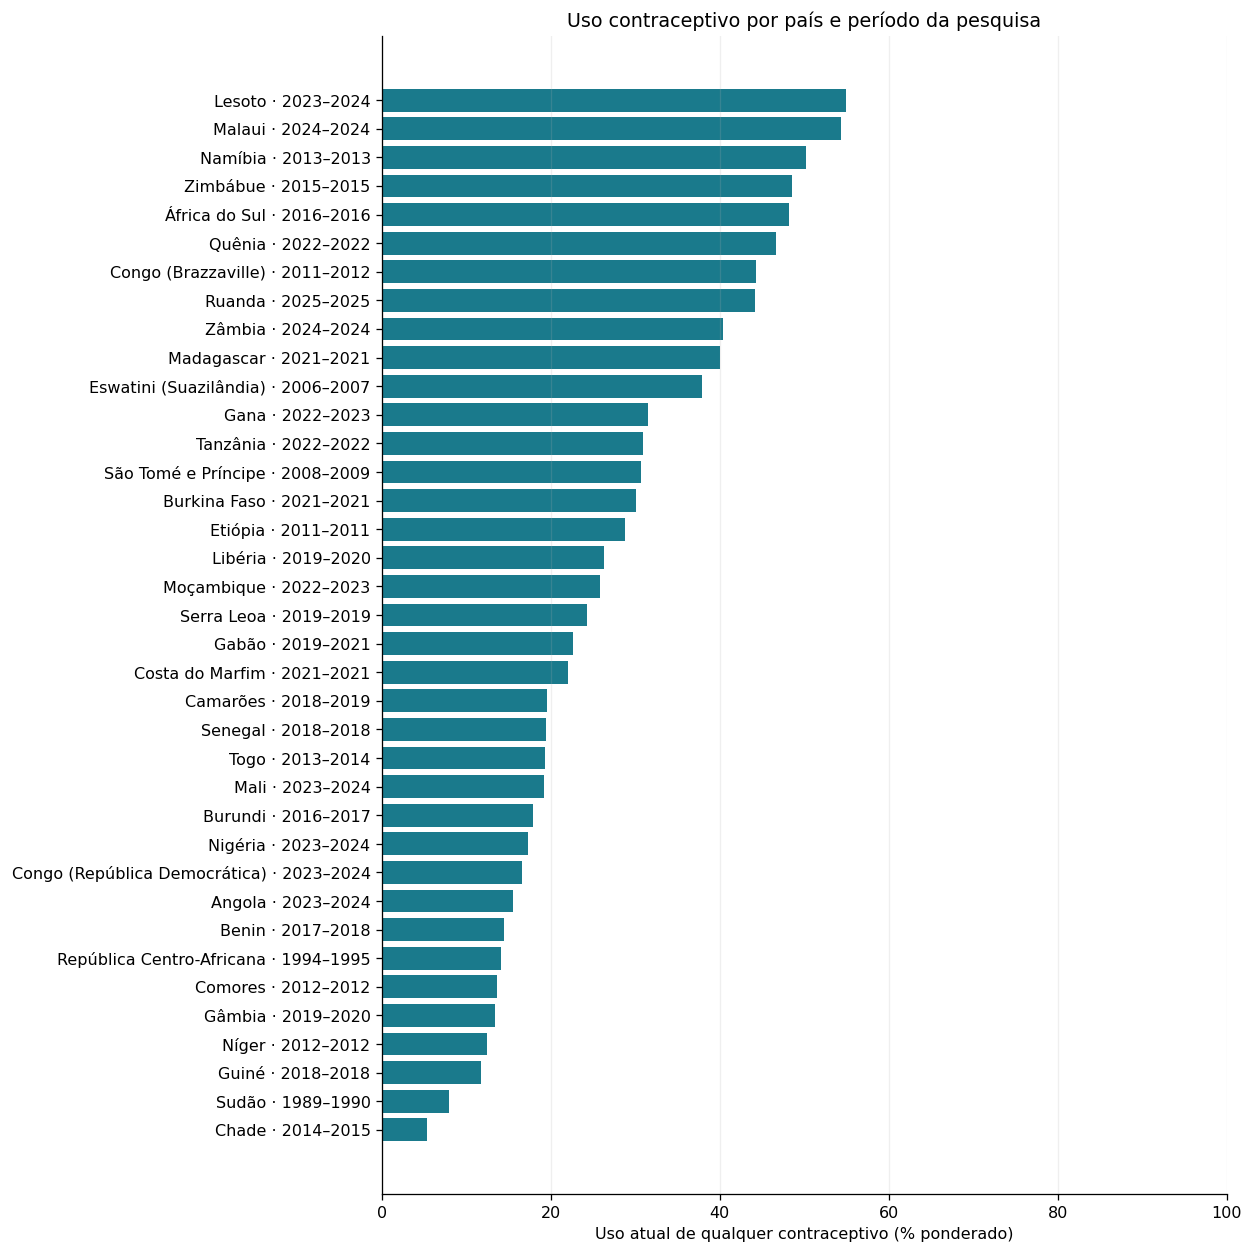

**Cobertura recuperada:** os 37 países têm respostas contraceptivas. A diferença entre países reúne contextos e anos distintos; ela sugere onde investigar, sem ordenar a qualidade das políticas públicas.

In [4]:
# Uma pesquisa temática por país; pesos calculados dentro dessa pesquisa.
panorama=consulta("""
SELECT p.codigo,p.nome,l.fase,MIN(e.ano) AS ano_min,MAX(e.ano) AS ano_max,
COUNT(*) AS entrevistas,SUM(e.usa_metodo IS NOT NULL AND e.peso>0) AS respostas_validas,
ROUND(100.0*SUM(CASE WHEN e.usa_metodo IS NOT NULL AND e.peso>0 THEN e.peso*e.usa_metodo END)/
NULLIF(SUM(CASE WHEN e.usa_metodo IS NOT NULL AND e.peso>0 THEN e.peso END),0),2) AS uso_percentual
FROM Entrevista e JOIN Mulher m ON m.id=e.mulher_id JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id JOIN Pais p ON p.codigo=l.pais_codigo
WHERE e.coorte!='nucleo_exclusivo' GROUP BY p.codigo,p.nome,l.fase ORDER BY p.nome
""")
assert len(panorama)==37 and panorama.uso_percentual.notna().all()
fig,ax=plt.subplots(figsize=(11,11))
ordenado=panorama.sort_values('uso_percentual')
rotulos=ordenado.nome+' · '+ordenado.ano_min.astype(str)+'–'+ordenado.ano_max.astype(str)
ax.barh(rotulos,ordenado.uso_percentual,color='#1a7a8c')
ax.set_xlabel('Uso atual de qualquer contraceptivo (% ponderado)')
ax.set_xlim(0,100)
ax.set_title('Uso contraceptivo por país e período da pesquisa')
ax.grid(axis='x',alpha=.2); fig.tight_layout(); display(fig); plt.close(fig)
display(Markdown('**Cobertura recuperada:** os 37 países têm respostas contraceptivas. A diferença entre países reúne contextos e anos distintos; ela sugere onde investigar, sem ordenar a qualidade das políticas públicas.'))


# 4. Diagrama ER

**9 entidades e 8 relacionamentos.** Mulher–Método é **M:N**, com atributo nível de conhecimento. Domicilio, Morador, Mulher, Entrevista, Nascimento, Crianca e Metodo têm identificador e pelo menos dois atributos próprios; Pais e Levantamento são dimensões de apoio.


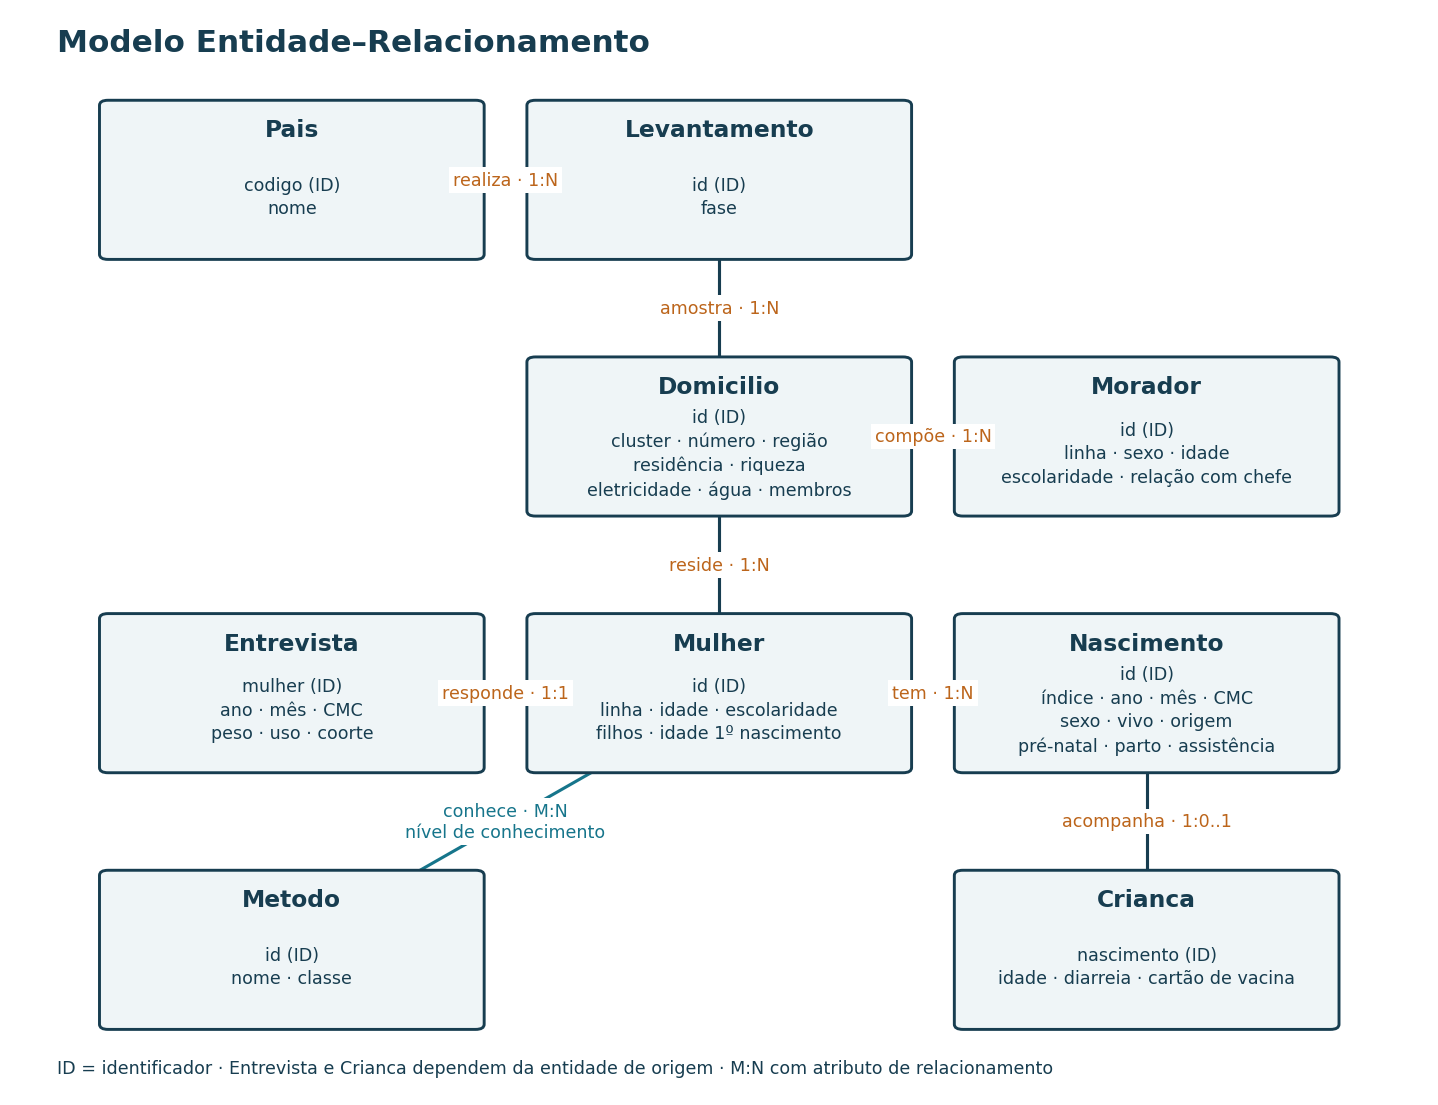

In [5]:
vinculos=consulta("""
SELECT (SELECT COUNT(*) FROM Conhecimento_Metodo WHERE nivel>0) AS vinculos_positivos,
       (SELECT COUNT(*) FROM (SELECT mulher_id FROM Conhecimento_Metodo WHERE nivel>0 GROUP BY mulher_id HAVING COUNT(*)>1)) AS mulheres_conhecem_varios,
       (SELECT COUNT(*) FROM (SELECT metodo_id FROM Conhecimento_Metodo WHERE nivel>0 GROUP BY metodo_id HAVING COUNT(*)>1)) AS metodos_conhecidos_por_varias
""")
assert vinculos.mulheres_conhecem_varios.iloc[0]>0 and vinculos.metodos_conhecidos_por_varias.iloc[0]==9
display(Markdown(f"**M:N verificado:** {int(vinculos.iloc[0,0]):,} vínculos de conhecimento positivo. A carga também verifica PK/FK."))


vinculos_positivos,mulheres_conhecem_varios,metodos_conhecidos_por_varias
2851767,459441,9


**M:N verificado:** 2,851,767 vínculos de conhecimento positivo. A carga também verifica PK/FK.

# 5. Diagrama relacional

**10 relações em 3FN.** `Conhecimento_Metodo` implementa o M:N com PK composta. `Entrevista` e `Crianca` compartilham a chave de suas entidades de origem. PK/FK, UNIQUE e CHECK são conferidos na carga.


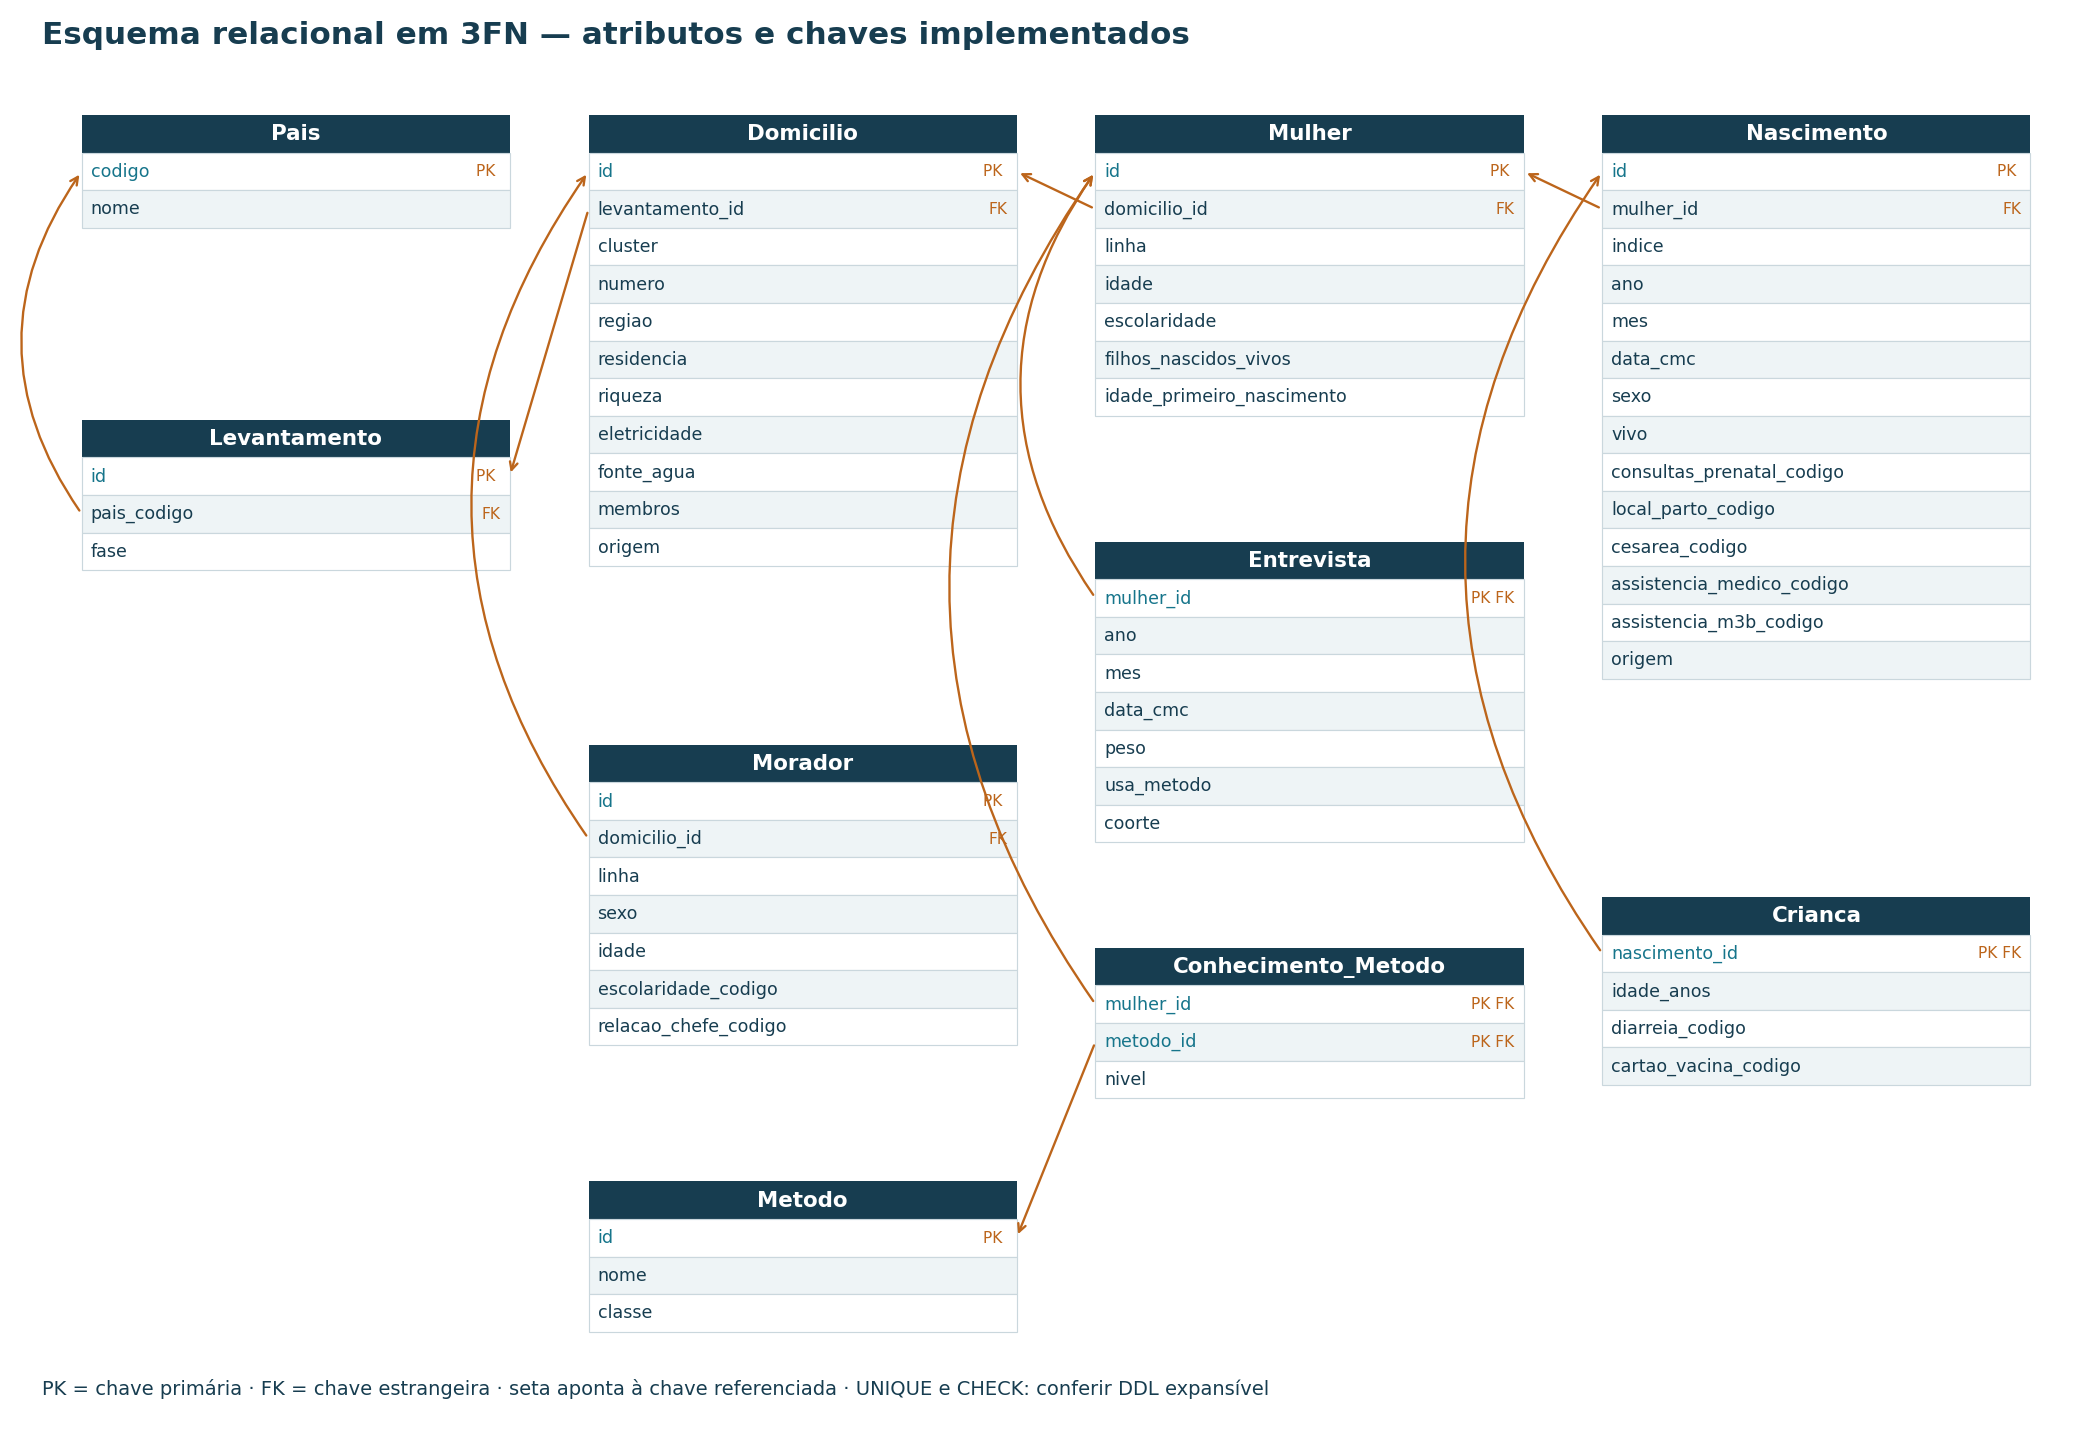

In [6]:
restricoes=consulta("""
SELECT name AS tabela, sql AS definicao_implementada
FROM sqlite_master WHERE type='table' ORDER BY name
""")

tabela,definicao_implementada
Conhecimento_Metodo,"CREATE TABLE Conhecimento_Metodo(\n mulher_id TEXT NOT NULL REFERENCES Mulher(id), metodo_id INTEGER NOT NULL REFERENCES Metodo(id),\n nivel INTEGER NOT NULL CHECK(nivel BETWEEN 0 AND 7), PRIMARY KEY(mulher_id,metodo_id)) WITHOUT ROWID"
Crianca,"CREATE TABLE Crianca(\n nascimento_id TEXT PRIMARY KEY REFERENCES Nascimento(id), idade_anos INTEGER,\n diarreia_codigo INTEGER, cartao_vacina_codigo INTEGER)"
Domicilio,"CREATE TABLE Domicilio(\n id TEXT PRIMARY KEY, levantamento_id TEXT NOT NULL REFERENCES Levantamento(id),\n cluster INTEGER NOT NULL, numero INTEGER NOT NULL, regiao INTEGER,\n residencia INTEGER CHECK(residencia IN(1,2)), riqueza INTEGER CHECK(riqueza BETWEEN 1 AND 5),\n eletricidade INTEGER CHECK(eletricidade IN(0,1)), fonte_agua INTEGER, membros INTEGER,\n origem TEXT NOT NULL CHECK(origem IN('HR','IR_sem_HR','IR_completo')),\n UNIQUE(levantamento_id,cluster,numero))"
Entrevista,"CREATE TABLE Entrevista(\n mulher_id TEXT PRIMARY KEY REFERENCES Mulher(id), ano INTEGER, mes INTEGER,\n data_cmc INTEGER, peso REAL CHECK(peso>0), usa_metodo INTEGER CHECK(usa_metodo IN(0,1)),\n coorte TEXT NOT NULL CHECK(coorte IN('nucleo_e_contracepcao','nucleo_exclusivo','contracepcao')))"
Levantamento,"CREATE TABLE Levantamento(id TEXT PRIMARY KEY, pais_codigo TEXT NOT NULL REFERENCES Pais(codigo), fase TEXT NOT NULL, UNIQUE(pais_codigo,fase))"
Metodo,"CREATE TABLE Metodo(\n id INTEGER PRIMARY KEY, nome TEXT NOT NULL UNIQUE, classe TEXT NOT NULL CHECK(classe IN('Moderno','Tradicional')))"
Morador,"CREATE TABLE Morador(\n id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,\n sexo INTEGER, idade INTEGER, escolaridade_codigo INTEGER, relacao_chefe_codigo INTEGER,\n UNIQUE(domicilio_id,linha))"
Mulher,"CREATE TABLE Mulher(\n id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,\n idade INTEGER, escolaridade INTEGER CHECK(escolaridade BETWEEN 0 AND 3),\n filhos_nascidos_vivos INTEGER, idade_primeiro_nascimento INTEGER,\n UNIQUE(domicilio_id,linha))"
Nascimento,"CREATE TABLE Nascimento(\n id TEXT PRIMARY KEY, mulher_id TEXT NOT NULL REFERENCES Mulher(id), indice INTEGER NOT NULL CHECK(indice>=1),\n ano INTEGER, mes INTEGER, data_cmc INTEGER, sexo INTEGER CHECK(sexo IN(1,2)), vivo INTEGER CHECK(vivo IN(0,1)),\n consultas_prenatal_codigo INTEGER, local_parto_codigo INTEGER, cesarea_codigo INTEGER,\n assistencia_medico_codigo INTEGER, assistencia_m3b_codigo INTEGER,\n origem TEXT NOT NULL CHECK(origem IN('BR','KR_sem_BR')), UNIQUE(mulher_id,indice))"
Pais,"CREATE TABLE Pais(codigo TEXT PRIMARY KEY, nome TEXT NOT NULL UNIQUE)"


# 6. Consultas, resultados e análise

**10 consultas:** 2 seleção/projeção · 3 junções de duas relações · 3 junções de ≥3 relações · 2 agregações sobre junções.

SQL e gráficos ficam visíveis; resultados completos podem ser expandidos. Consultas 1–2 mostram registros selecionados, sem estimar prevalência.

**Leitura:** Q3/5/6/7 são amostrais não ponderadas; Q4/8/9/10 usam pesos. Quintis de riqueza são relativos a cada país. Sudão permanece no inventário, mas não nas comparações rural–urbano/riqueza por falta de informação. Q4/8/9 usam a pesquisa contraceptiva; Q3/6/7/10 mantêm o núcleo. Ausências e estratos pequenos ficam explícitos nos gráficos.


## 6.1 Duas consultas com seleção e projeção

### 6.1.1 Consulta 1

Seleção e projeção: adolescentes de 15–19 anos sem escolaridade. A identificação técnica começa pelo código do país; somente Mulher é consultada.

```sql
SELECT substr(id,1,2) AS pais_codigo,id AS mulher_id,idade,idade_primeiro_nascimento,filhos_nascidos_vivos
FROM Mulher
WHERE idade BETWEEN 15
AND 19
AND escolaridade=0
ORDER BY id
```

pais_codigo,mulher_id,idade,idade_primeiro_nascimento,filhos_nascidos_vivos
AO,AO_81|100|13|4,18,NaN,0
BF,BF_81|100|273|7,17,NaN,0
BJ,BJ_71|101|116|3,16,NaN,0
BU,BU_71|101|1615|2,18,18.0,1
CD,CD_81|100|122|3,15,NaN,0
CF,CF_31|101|7|11,16,NaN,0
CG,CG_61|103|1|4,19,NaN,0
CI,CI_81|101|4|8,15,NaN,0
CM,CM_71|105|446|2,17,16.0,1
ET,ET_81|102|32|2,19,19.0,1


pais_codigo,registros
AO,457
BF,1087
BJ,956
BU,284
CD,469
CF,520
CG,98
CI,870
CM,506
ET,304


**Resultado:** 21,043 registros. Dados integrais em `r1`/`r2` após execução.

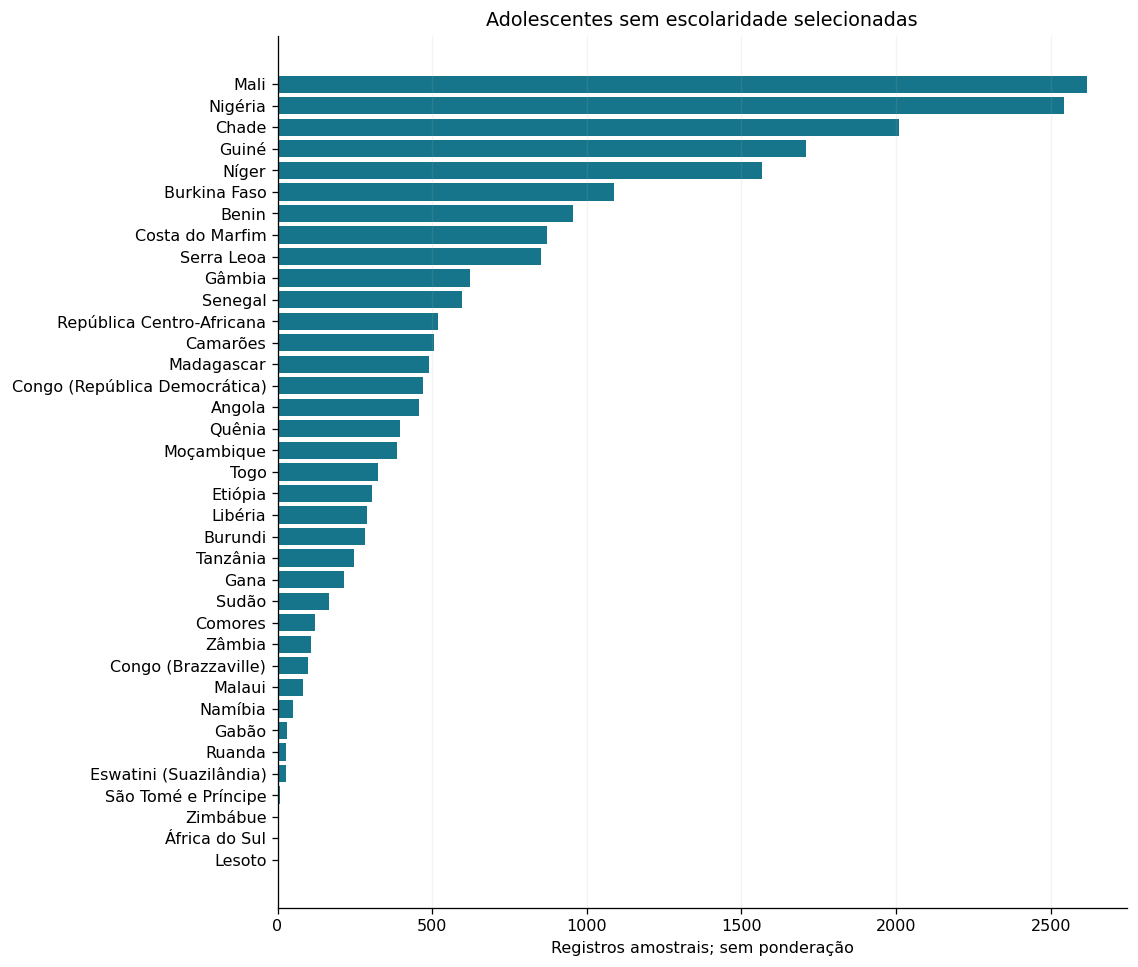

In [7]:
sql_1 = """
SELECT substr(id,1,2) AS pais_codigo,id AS mulher_id,idade,idade_primeiro_nascimento,filhos_nascidos_vivos
FROM Mulher
WHERE idade BETWEEN 15
AND 19
AND escolaridade=0
ORDER BY id
"""
display(Markdown("```sql\n"+sql_1.strip()+"\n```"))
r1 = consulta(sql_1, amostra=True)
barras(r1.groupby('pais_codigo').size().rename(index=nomes),'Adolescentes sem escolaridade selecionadas','Registros amostrais; sem ponderação')


In [8]:
display(Markdown(f"**Leitura:** a consulta 1 encontrou {len(r1):,} registros elegíveis em {r1.pais_codigo.nunique()} países. As contagens são da amostra; diferenças no tamanho das pesquisas impedem comparar os totais como prevalências."))

**Leitura:** a consulta 1 encontrou 21,043 registros elegíveis em 37 países. As contagens são da amostra; diferenças no tamanho das pesquisas impedem comparar os totais como prevalências.

### 6.1.2 Consulta 2

Seleção e projeção: domicílios rurais no quintil mais pobre, sem eletricidade. Ausência de HR não conta como ausência de eletricidade.

```sql
SELECT substr(id,1,2) AS pais_codigo,id AS domicilio_id,fonte_agua,membros
FROM Domicilio
WHERE residencia=2
AND riqueza=1
AND eletricidade=0
ORDER BY id
```

pais_codigo,domicilio_id,fonte_agua,membros
AO,AO_81|101|17,43.0,2
BF,BF_81|11|20,21.0,5
BJ,BJ_71|100|130,14.0,3
BU,BU_71|101|1476,32.0,3
CD,CD_81|100|102,42.0,4
CG,CG_61|101|11,13.0,1
CI,CI_81|100|10,21.0,7
CM,CM_82|136|10,42.0,4
ET,ET_81|100|10,42.0,5
GA,GA_71|103|1,43.0,2


pais_codigo,registros
AO,4159
BF,2195
BJ,1840
BU,3305
CD,7091
CG,4987
CI,2554
CM,867
ET,1960
GA,2394


**Resultado:** 75,029 registros. Dados integrais em `r1`/`r2` após execução.

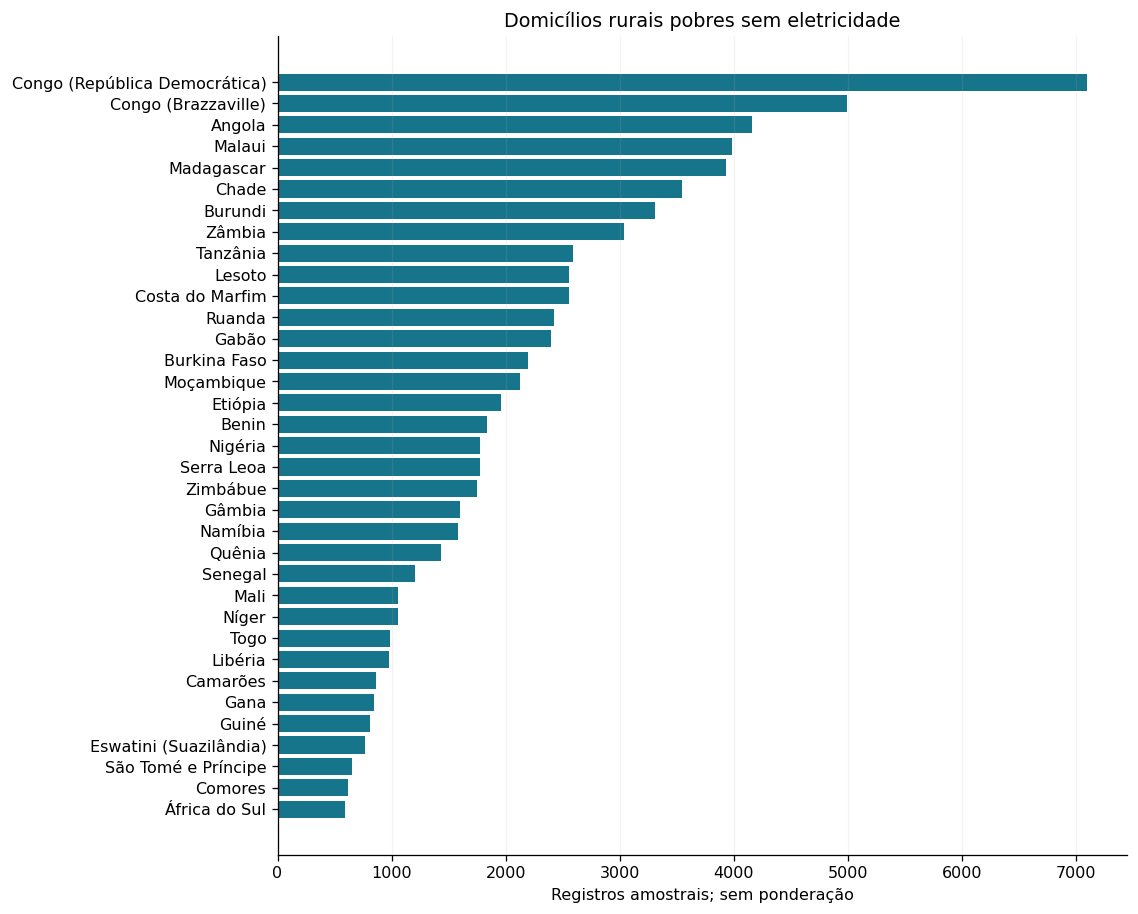

In [9]:
sql_2 = """
SELECT substr(id,1,2) AS pais_codigo,id AS domicilio_id,fonte_agua,membros
FROM Domicilio
WHERE residencia=2
AND riqueza=1
AND eletricidade=0
ORDER BY id
"""
display(Markdown("```sql\n"+sql_2.strip()+"\n```"))
r2 = consulta(sql_2, amostra=True)
barras(r2.groupby('pais_codigo').size().rename(index=nomes),'Domicílios rurais pobres sem eletricidade','Registros amostrais; sem ponderação')


In [10]:
display(Markdown(f"**Leitura:** a consulta 2 encontrou {len(r2):,} registros elegíveis em {r2.pais_codigo.nunique()} países. As contagens são da amostra; diferenças no tamanho das pesquisas impedem comparar os totais como prevalências."))

**Leitura:** a consulta 2 encontrou 75,029 registros elegíveis em 35 países. As contagens são da amostra; diferenças no tamanho das pesquisas impedem comparar os totais como prevalências.

## 6.2 Três consultas com junção de duas relações

### 6.2.1 Consulta 3

Junção de duas relações (Mulher–Domicilio): composição demográfica rural e urbana em cada país. Média de filhos é descritiva e não uma taxa de fecundidade.

```sql
SELECT substr(d.id,1,2) AS pais_codigo,CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
COUNT(*) AS mulheres,ROUND(AVG(m.idade),2) AS idade_media,
ROUND(AVG(m.filhos_nascidos_vivos),2) AS filhos_medios,
ROUND(100.0*SUM(m.escolaridade=0)/NULLIF(SUM(m.escolaridade IS NOT NULL),0),2) AS percentual_sem_escola
FROM Mulher m
JOIN Domicilio d ON d.id=m.domicilio_id
WHERE d.origem!='IR_completo'
AND d.residencia IN(1,2)
GROUP BY substr(d.id,1,2),d.residencia
ORDER BY pais_codigo,d.residencia
```

pais_codigo,residencia,mulheres,idade_media,filhos_medios,percentual_sem_escola
AO,Urbano,9066,26.87,2.19,10.07
AO,Rural,5651,27.99,3.17,40.93
BF,Urbano,6227,27.98,2.01,36.29
BF,Rural,11432,29.23,3.17,69.93
BJ,Urbano,7045,28.59,2.51,42.60
BJ,Rural,8883,28.46,3.17,64.85
BU,Urbano,3671,27.20,1.94,13.38
BU,Rural,13598,28.41,2.82,39.62
CD,Urbano,9146,27.41,2.30,5.18
CD,Rural,18437,28.40,3.25,23.77


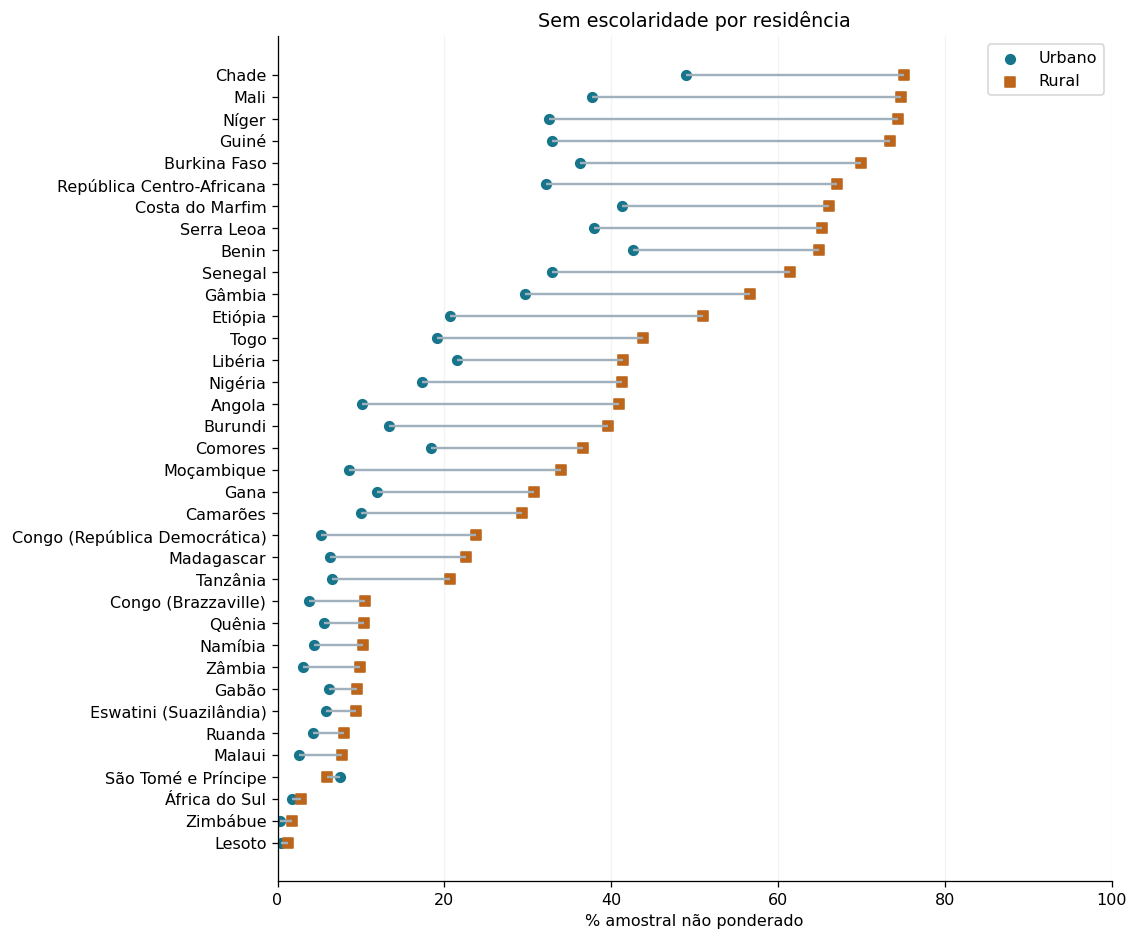

In [11]:
sql_3 = """
SELECT substr(d.id,1,2) AS pais_codigo,CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
COUNT(*) AS mulheres,ROUND(AVG(m.idade),2) AS idade_media,
ROUND(AVG(m.filhos_nascidos_vivos),2) AS filhos_medios,
ROUND(100.0*SUM(m.escolaridade=0)/NULLIF(SUM(m.escolaridade IS NOT NULL),0),2) AS percentual_sem_escola
FROM Mulher m
JOIN Domicilio d ON d.id=m.domicilio_id
WHERE d.origem!='IR_completo'
AND d.residencia IN(1,2)
GROUP BY substr(d.id,1,2),d.residencia
ORDER BY pais_codigo,d.residencia
"""
display(Markdown("```sql\n"+sql_3.strip()+"\n```"))
r3 = consulta(sql_3, amostra=False)
pares(nomear(r3.pivot(index='pais_codigo',columns='residencia',values='percentual_sem_escola')),'Urbano','Rural','Sem escolaridade por residência','% amostral não ponderado')


In [12]:
comparacao=r3.pivot(index='pais_codigo',columns='residencia',values='percentual_sem_escola').dropna()
maior=(comparacao.Rural>comparacao.Urbano).sum()
display(Markdown(f"**Leitura:** a proporção não ponderada de mulheres sem escola é maior no meio rural em {maior} de {len(comparacao)} países com ambas as áreas. Essa composição deve ser considerada antes de atribuir as diferenças contraceptivas apenas ao território."))

**Leitura:** a proporção não ponderada de mulheres sem escola é maior no meio rural em 35 de 36 países com ambas as áreas. Essa composição deve ser considerada antes de atribuir as diferenças contraceptivas apenas ao território.

### 6.2.2 Consulta 4

Junção de duas relações (Entrevista–Mulher): uso de algum contraceptivo por nível de escolaridade em cada país. O denominador usa resposta válida e peso positivo.

A seleção pela coorte evita reunir entrevistas de duas pesquisas do mesmo país.


```sql
SELECT substr(m.id,1,2) AS pais_codigo,m.escolaridade,COUNT(*) AS respostas_validas,
ROUND(100.0*SUM(e.peso*e.usa_metodo)/SUM(e.peso),2) AS percentual_uso_ponderado
FROM Entrevista e
JOIN Mulher m ON m.id=e.mulher_id
WHERE e.coorte!='nucleo_exclusivo'
AND e.usa_metodo IS NOT NULL
AND e.peso>0
AND m.escolaridade IS NOT NULL
GROUP BY substr(m.id,1,2),m.escolaridade
ORDER BY pais_codigo,m.escolaridade
```

pais_codigo,escolaridade,respostas_validas,percentual_uso_ponderado
AO,0,3226,5.31
AO,1,4149,10.82
AO,2,6747,20.30
AO,3,595,28.28
BF,0,10254,29.04
BF,1,2515,31.30
BF,2,4548,30.46
BF,3,342,43.92
BJ,0,8762,12.42
BJ,1,3116,14.57


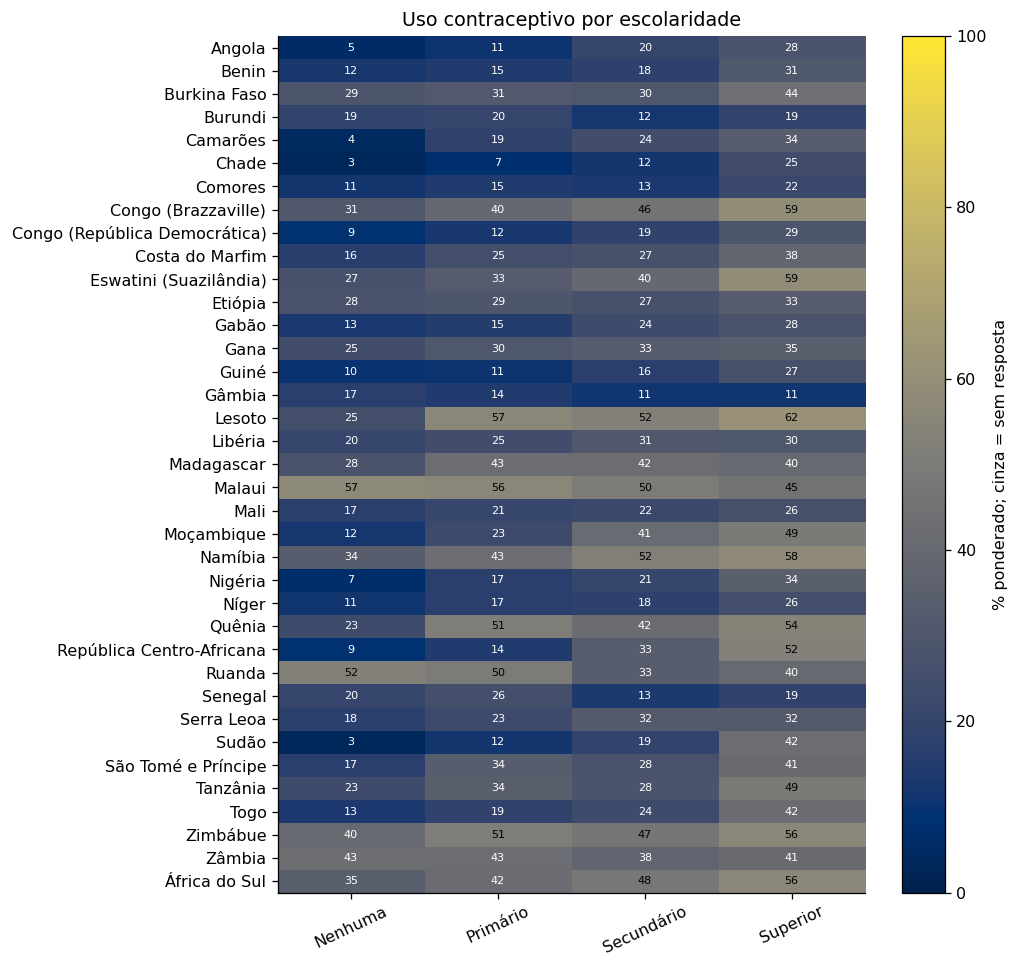

In [13]:
sql_4 = """
SELECT substr(m.id,1,2) AS pais_codigo,m.escolaridade,COUNT(*) AS respostas_validas,
ROUND(100.0*SUM(e.peso*e.usa_metodo)/SUM(e.peso),2) AS percentual_uso_ponderado
FROM Entrevista e
JOIN Mulher m ON m.id=e.mulher_id
WHERE e.coorte!='nucleo_exclusivo'
AND e.usa_metodo IS NOT NULL
AND e.peso>0
AND m.escolaridade IS NOT NULL
GROUP BY substr(m.id,1,2),m.escolaridade
ORDER BY pais_codigo,m.escolaridade
"""
display(Markdown("```sql\n"+sql_4.strip()+"\n```"))
r4 = consulta(sql_4, amostra=False)
mapa(nomear(r4.pivot(index='pais_codigo',columns='escolaridade',values='percentual_uso_ponderado')).rename(columns={0:'Nenhuma',1:'Primário',2:'Secundário',3:'Superior'}),'Uso contraceptivo por escolaridade','% ponderado; cinza = sem resposta')


In [14]:
extremos=r4[r4.escolaridade.isin([0,3])].pivot(index='pais_codigo',columns='escolaridade',values='percentual_uso_ponderado').dropna()
display(Markdown(f"**Leitura:** entre os {len(extremos)} países com respostas nos dois extremos de escolaridade, {int((extremos[3]>extremos[0]).sum())} apresentam maior uso ponderado no nível superior do que entre mulheres sem escola. Idade, estado conjugal, preferências reprodutivas e acesso podem explicar parte da associação."))

**Leitura:** entre os 37 países com respostas nos dois extremos de escolaridade, 31 apresentam maior uso ponderado no nível superior do que entre mulheres sem escola. Idade, estado conjugal, preferências reprodutivas e acesso podem explicar parte da associação.

### 6.2.3 Consulta 5

Junção de duas relações (Conhecimento_Metodo–Metodo): conhecimento dos nove métodos por país. Cada denominador contém quem respondeu àquele método; percentuais não ponderados, pois esta categoria usa somente duas relações.

Os resultados são separados por levantamento para não misturar ondas de coleta.


```sql
SELECT substr(k.mulher_id,1,2) AS pais_codigo,substr(k.mulher_id,1,instr(k.mulher_id,'|')-1) AS levantamento,t.nome,t.classe,COUNT(*) AS respostas_validas,
SUM(k.nivel>0) AS conhecem,ROUND(100.0*SUM(k.nivel>0)/COUNT(*),2) AS percentual_conhecimento
FROM Conhecimento_Metodo k
JOIN Metodo t ON t.id=k.metodo_id
GROUP BY substr(k.mulher_id,1,2),levantamento,t.id,t.nome,t.classe
ORDER BY pais_codigo,t.id
```

pais_codigo,levantamento,nome,classe,respostas_validas,conhecem,percentual_conhecimento
AO,AO_81,Pílula,Moderno,14717,9755,66.28
AO,AO_81,DIU,Moderno,14717,5486,37.28
AO,AO_81,Injetáveis,Moderno,14717,9511,64.63
AO,AO_81,Preservativo masculino,Moderno,14717,11692,79.45
AO,AO_81,Esterilização feminina,Moderno,14717,3215,21.85
AO,AO_81,Esterilização masculina,Moderno,14717,2307,15.68
AO,AO_81,Abstinência periódica,Tradicional,14717,4959,33.70
AO,AO_81,Coito interrompido,Tradicional,14717,5447,37.01
BF,BF_81,Pílula,Moderno,17659,15830,89.64
BF,BF_81,DIU,Moderno,17659,10978,62.17


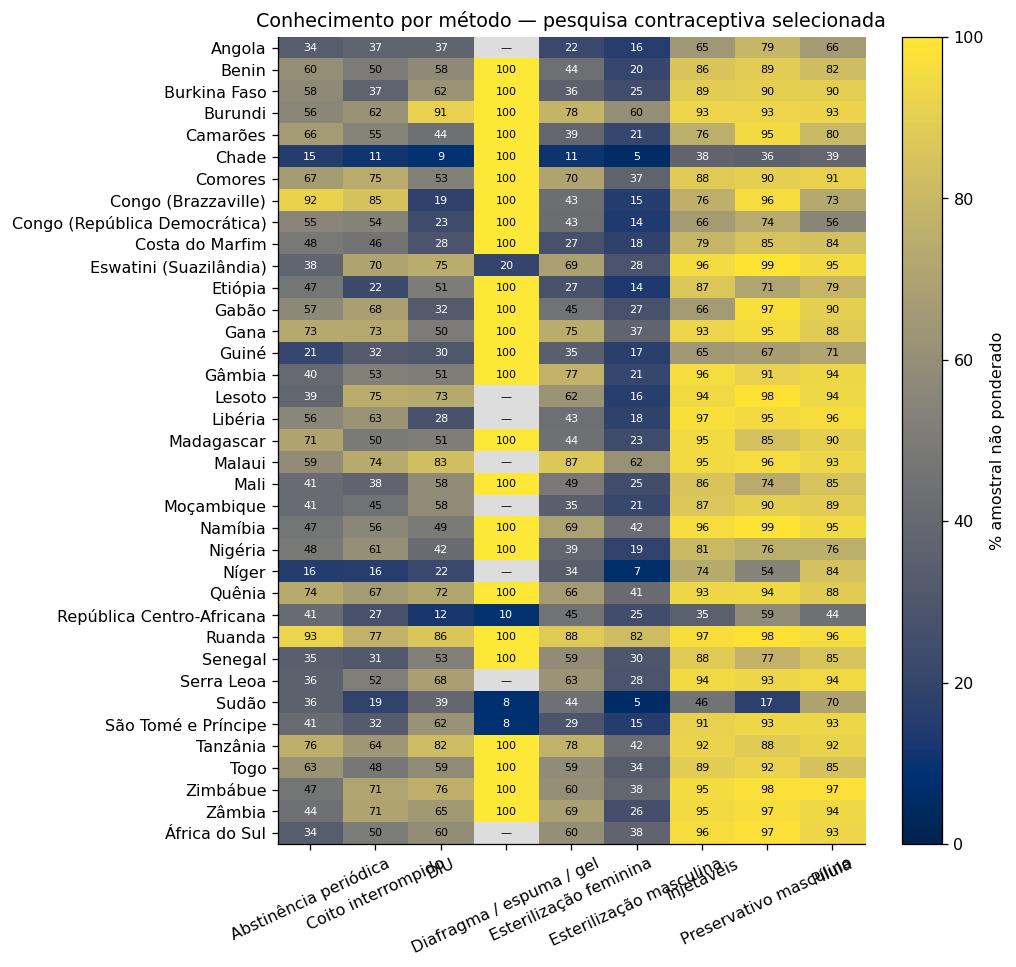

In [15]:
sql_5 = """
SELECT substr(k.mulher_id,1,2) AS pais_codigo,substr(k.mulher_id,1,instr(k.mulher_id,'|')-1) AS levantamento,t.nome,t.classe,COUNT(*) AS respostas_validas,
SUM(k.nivel>0) AS conhecem,ROUND(100.0*SUM(k.nivel>0)/COUNT(*),2) AS percentual_conhecimento
FROM Conhecimento_Metodo k
JOIN Metodo t ON t.id=k.metodo_id
GROUP BY substr(k.mulher_id,1,2),levantamento,t.id,t.nome,t.classe
ORDER BY pais_codigo,t.id
"""
display(Markdown("```sql\n"+sql_5.strip()+"\n```"))
r5 = consulta(sql_5, amostra=False)
escolha=panorama.assign(levantamento=panorama.codigo+'_'+panorama.fase.astype(str))[['codigo','levantamento']]
visual=r5.merge(escolha,on='levantamento',validate='many_to_one')
mapa(nomear(visual.pivot(index='pais_codigo',columns='nome',values='percentual_conhecimento')),'Conhecimento por método — pesquisa contraceptiva selecionada','% amostral não ponderado')


In [16]:
display(Markdown(f"**Leitura:** o M:N contém respostas válidas em {r5.pais_codigo.nunique()} países. As categorias de conhecimento variam na cobertura; não comparar a soma de todos os métodos como se fosse número de mulheres nem presumir que conhecimento resulta em uso."))

**Leitura:** o M:N contém respostas válidas em 37 países. As categorias de conhecimento variam na cobertura; não comparar a soma de todos os métodos como se fosse número de mulheres nem presumir que conhecimento resulta em uso.

## 6.3 Três consultas com junção de três ou mais relações

### 6.3.1 Consulta 6

Junção de cinco relações: pobreza material e escolaridade por país e residência, para distinguir composição socioeconômica de diferenças de saúde.

```sql
SELECT p.codigo,p.nome,CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
COUNT(*) AS mulheres,ROUND(100.0*SUM(d.riqueza=1)/NULLIF(SUM(d.riqueza IS NOT NULL),0),2) AS percentual_quintil_1,
ROUND(100.0*SUM(d.eletricidade=0)/NULLIF(SUM(d.eletricidade IS NOT NULL),0),2) AS percentual_sem_eletricidade,
ROUND(100.0*SUM(m.escolaridade=0)/NULLIF(SUM(m.escolaridade IS NOT NULL),0),2) AS percentual_sem_escola
FROM Entrevista e
JOIN Mulher m ON m.id=e.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id
JOIN Pais p ON p.codigo=l.pais_codigo
WHERE e.coorte!='contracepcao'
AND d.residencia IN(1,2)
GROUP BY p.codigo,p.nome,d.residencia
ORDER BY p.nome,d.residencia
```

codigo,nome,residencia,mulheres,percentual_quintil_1,percentual_sem_eletricidade,percentual_sem_escola
AO,Angola,Urbano,9066,1.18,19.17,10.07
AO,Angola,Rural,5651,52.45,87.65,40.93
BJ,Benin,Urbano,7045,13.03,42.19,42.60
BJ,Benin,Rural,8883,21.82,77.43,64.85
BF,Burkina Faso,Urbano,6227,1.08,45.85,36.29
BF,Burkina Faso,Rural,11432,24.51,93.19,69.93
BU,Burundi,Urbano,3671,3.84,40.42,13.38
BU,Burundi,Rural,13598,21.00,97.56,39.62
CM,Camarões,Urbano,3755,2.45,12.52,9.99
CM,Camarões,Rural,2777,35.22,64.60,29.28


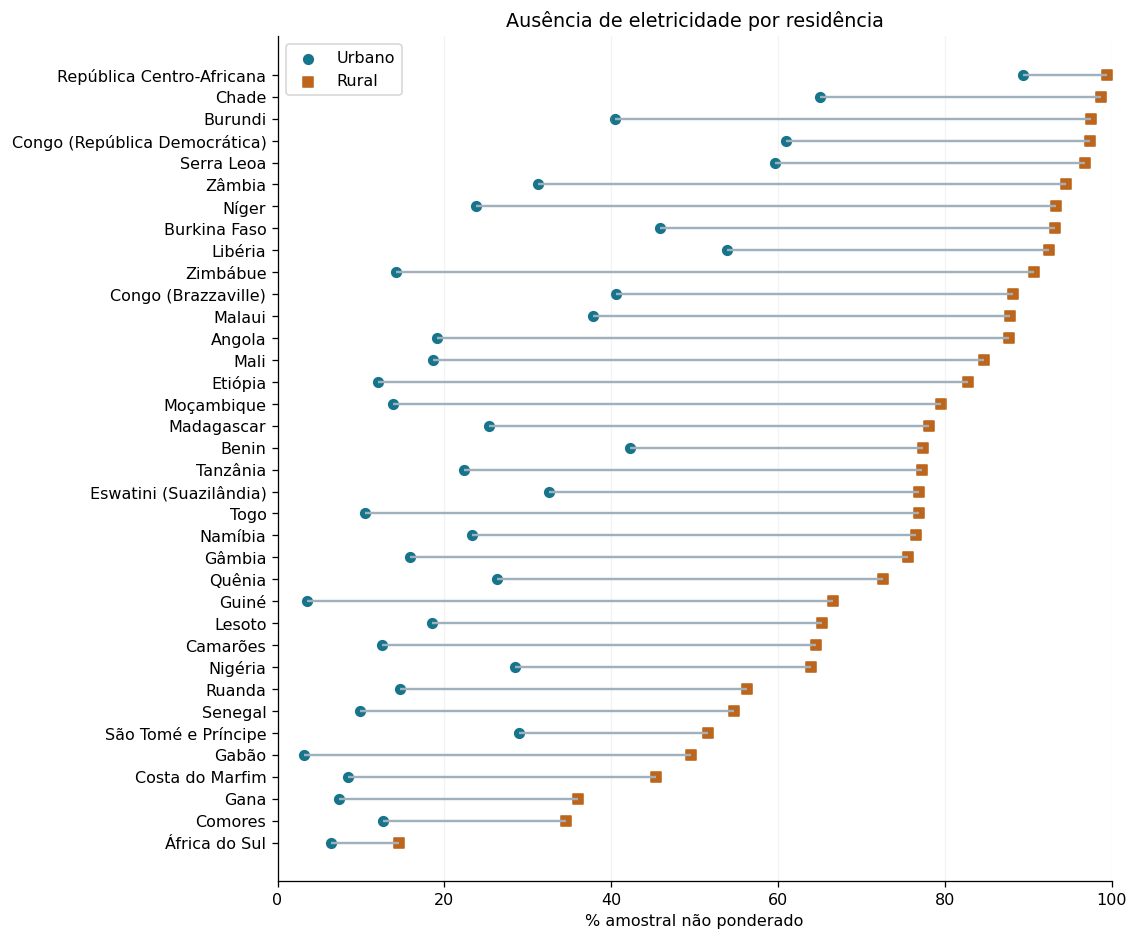

In [17]:
sql_6 = """
SELECT p.codigo,p.nome,CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
COUNT(*) AS mulheres,ROUND(100.0*SUM(d.riqueza=1)/NULLIF(SUM(d.riqueza IS NOT NULL),0),2) AS percentual_quintil_1,
ROUND(100.0*SUM(d.eletricidade=0)/NULLIF(SUM(d.eletricidade IS NOT NULL),0),2) AS percentual_sem_eletricidade,
ROUND(100.0*SUM(m.escolaridade=0)/NULLIF(SUM(m.escolaridade IS NOT NULL),0),2) AS percentual_sem_escola
FROM Entrevista e
JOIN Mulher m ON m.id=e.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id
JOIN Pais p ON p.codigo=l.pais_codigo
WHERE e.coorte!='contracepcao'
AND d.residencia IN(1,2)
GROUP BY p.codigo,p.nome,d.residencia
ORDER BY p.nome,d.residencia
"""
display(Markdown("```sql\n"+sql_6.strip()+"\n```"))
r6 = consulta(sql_6, amostra=False)
pares(r6.pivot(index='nome',columns='residencia',values='percentual_sem_eletricidade'),'Urbano','Rural','Ausência de eletricidade por residência','% amostral não ponderado')


In [18]:
material=r6.pivot(index='codigo',columns='residencia',values='percentual_sem_eletricidade').dropna()
display(Markdown(f"**Leitura:** a falta de eletricidade é mais frequente no meio rural em {int((material.Rural>material.Urbano).sum())} de {len(material)} países com informação nas duas áreas. O Sudão não possui HR neste recorte e não entra nessa comparação habitacional; seu dado ausente não é eletricidade presente."))

**Leitura:** a falta de eletricidade é mais frequente no meio rural em 36 de 36 países com informação nas duas áreas. O Sudão não possui HR neste recorte e não entra nessa comparação habitacional; seu dado ausente não é eletricidade presente.

### 6.3.2 Consulta 7

Junção de seis relações: disponibilidade da informação de pré-natal em nascimentos recentes. A análise usa somente o nascimento mais recente (índice 1), ocorrido nos 60 meses anteriores à entrevista, e distingue códigos ausentes/especiais.

```sql
SELECT p.codigo,p.nome,CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
COUNT(*) AS nascimentos_recentes,SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0
AND 90 THEN 1 ELSE 0 END) AS respostas_validas,
ROUND(100.0*SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0
AND 90 THEN 1 ELSE 0 END)/COUNT(*),2) AS cobertura_resposta_percentual
FROM Entrevista e
JOIN Mulher m ON m.id=e.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id
JOIN Pais p ON p.codigo=l.pais_codigo
JOIN Nascimento n ON n.mulher_id=m.id
WHERE n.indice=1
AND e.data_cmc-n.data_cmc BETWEEN 0
AND 59
AND d.residencia IN(1,2)
GROUP BY p.codigo,p.nome,d.residencia
ORDER BY p.nome,d.residencia
```

codigo,nome,residencia,nascimentos_recentes,respostas_validas,cobertura_resposta_percentual
AO,Angola,Urbano,4208,2992,71.10
AO,Angola,Rural,3617,2865,79.21
BJ,Benin,Urbano,3628,3513,96.83
BJ,Benin,Rural,5349,5237,97.91
BF,Burkina Faso,Urbano,2777,1859,66.94
BF,Burkina Faso,Rural,6515,4525,69.46
BU,Burundi,Urbano,1478,1476,99.86
BU,Burundi,Rural,7161,7158,99.96
CM,Camarões,Urbano,1561,1122,71.88
CM,Camarões,Rural,1524,1202,78.87


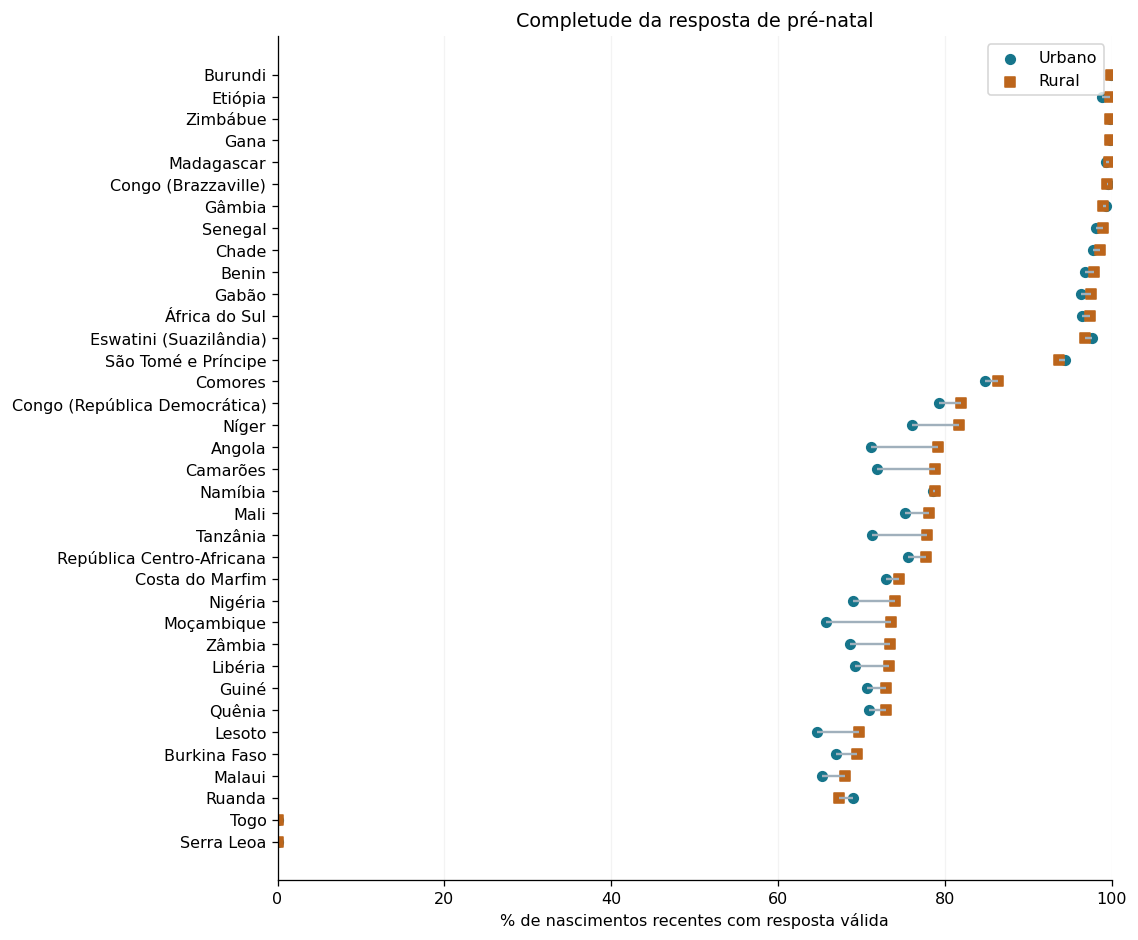

In [19]:
sql_7 = """
SELECT p.codigo,p.nome,CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
COUNT(*) AS nascimentos_recentes,SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0
AND 90 THEN 1 ELSE 0 END) AS respostas_validas,
ROUND(100.0*SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0
AND 90 THEN 1 ELSE 0 END)/COUNT(*),2) AS cobertura_resposta_percentual
FROM Entrevista e
JOIN Mulher m ON m.id=e.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id
JOIN Pais p ON p.codigo=l.pais_codigo
JOIN Nascimento n ON n.mulher_id=m.id
WHERE n.indice=1
AND e.data_cmc-n.data_cmc BETWEEN 0
AND 59
AND d.residencia IN(1,2)
GROUP BY p.codigo,p.nome,d.residencia
ORDER BY p.nome,d.residencia
"""
display(Markdown("```sql\n"+sql_7.strip()+"\n```"))
r7 = consulta(sql_7, amostra=False)
pares(r7.pivot(index='nome',columns='residencia',values='cobertura_resposta_percentual'),'Urbano','Rural','Completude da resposta de pré-natal','% de nascimentos recentes com resposta válida')


In [20]:
display(Markdown(f"**Leitura:** há nascimentos recentes em {r7.codigo.nunique()} países. A cobertura de respostas válidas de pré-natal varia de {r7.cobertura_resposta_percentual.min():.1f}% a {r7.cobertura_resposta_percentual.max():.1f}% entre os grupos país–residência. Um percentual de atendimento aparentemente alto pode descrever apenas a parte com informação registrada."))

**Leitura:** há nascimentos recentes em 36 países. A cobertura de respostas válidas de pré-natal varia de 0.0% a 100.0% entre os grupos país–residência. Um percentual de atendimento aparentemente alto pode descrever apenas a parte com informação registrada.

### 6.3.3 Consulta 8

Conhecimento de algum dos sete métodos modernos do recorte × uso atual de qualquer método, no mesmo denominador ponderado. A CTE resume o M:N em uma linha por mulher para evitar duplicação. Sem resposta positiva, o desconhecimento exige sete respostas válidas; respostas incompletas são excluídas. A distância entre indicadores não mede necessidade não atendida.


**Sensibilidade:** a rotina DHS considera `7` positivo, embora o rótulo indique método fora da tabela. Abaixo, repetimos o cálculo usando apenas códigos 0–3: é um recorte de respostas explícitas, com outro denominador, e não o indicador oficial de conhecimento moderno (`v301=3`).


```sql
WITH conhecimento AS (
SELECT k.mulher_id,CASE WHEN MAX(k.nivel>0)=1 THEN 1 WHEN COUNT(*)=7 THEN 0 END AS conhece_moderno
FROM Conhecimento_Metodo k
JOIN Metodo t ON t.id=k.metodo_id
WHERE t.classe='Moderno'
GROUP BY k.mulher_id)
SELECT p.codigo,p.nome,COUNT(*) AS mulheres_respostas_validas,
ROUND(100.0*SUM(e.peso*k.conhece_moderno)/SUM(e.peso),2) AS percentual_conhece_moderno,
ROUND(100.0*SUM(e.peso*e.usa_metodo)/SUM(e.peso),2) AS percentual_uso_qualquer
FROM Entrevista e
JOIN Mulher m ON m.id=e.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id
JOIN Pais p ON p.codigo=l.pais_codigo
JOIN conhecimento k ON k.mulher_id=m.id
WHERE e.coorte!='nucleo_exclusivo'
AND e.usa_metodo IS NOT NULL
AND e.peso>0
AND k.conhece_moderno IS NOT NULL
GROUP BY p.codigo,p.nome
ORDER BY p.nome
```

codigo,nome,mulheres_respostas_validas,percentual_conhece_moderno,percentual_uso_qualquer
AO,Angola,11999,100.00,18.26
BJ,Benin,15928,100.00,14.41
BF,Burkina Faso,17659,100.00,30.06
BU,Burundi,17269,100.00,17.89
CM,Camarões,13527,100.00,19.52
TD,Chade,17719,100.00,5.35
KM,Comores,5329,100.00,13.66
CG,Congo (Brazzaville),10819,100.00,44.34
CD,Congo (República Democrática),27583,100.00,16.55
CI,Costa do Marfim,14877,100.00,22.05


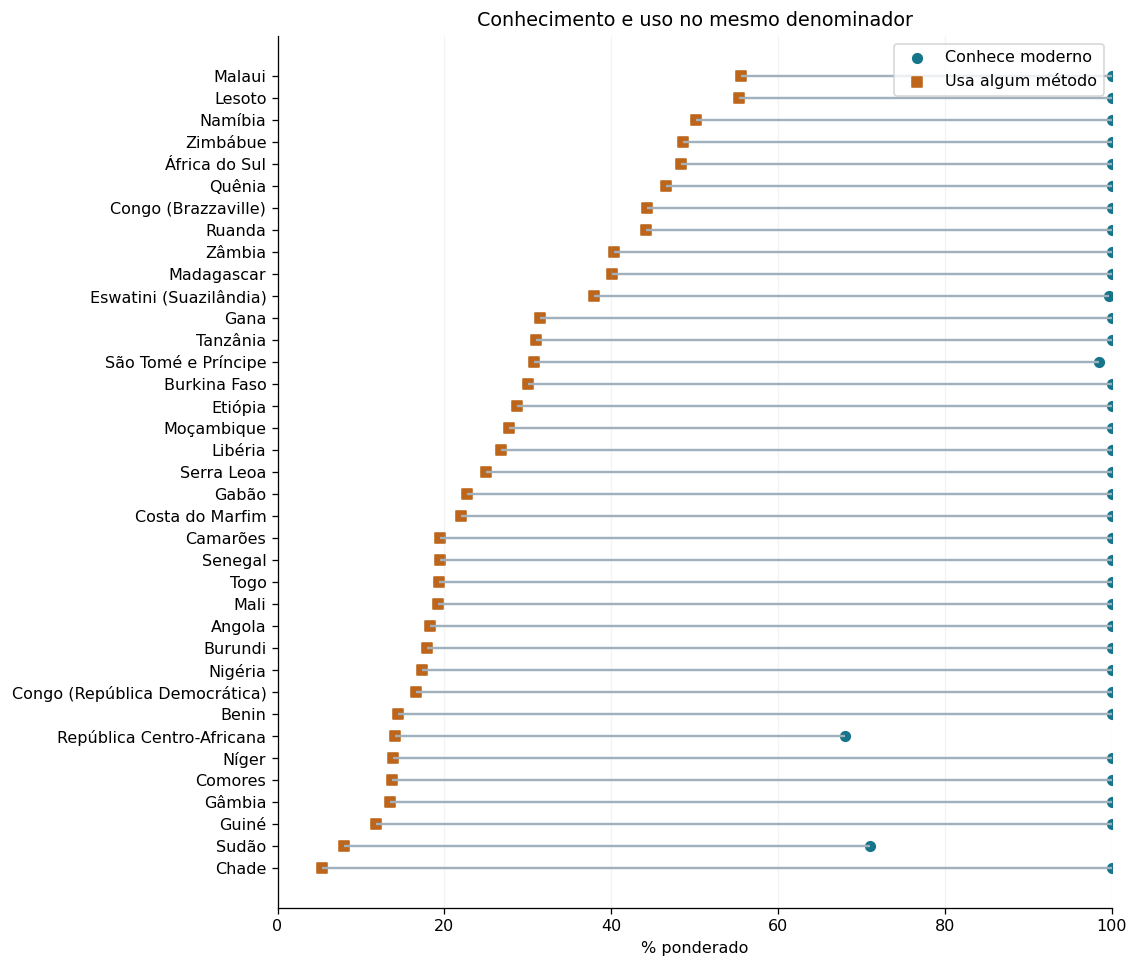

codigo,nome,mulheres_respostas_validas,percentual_conhece_moderno,percentual_uso_qualquer
AO,Angola,11999,100.00,18.26
BJ,Benin,14868,100.00,15.36
BF,Burkina Faso,16877,100.00,31.47
BU,Burundi,16735,100.00,18.43
CM,Camarões,12998,100.00,20.29
TD,Chade,8517,100.00,9.34
KM,Comores,5127,100.00,14.23
CG,Congo (Brazzaville),10509,100.00,45.12
CD,Congo (República Democrática),22477,100.00,19.19
CI,Costa do Marfim,13363,100.00,24.03


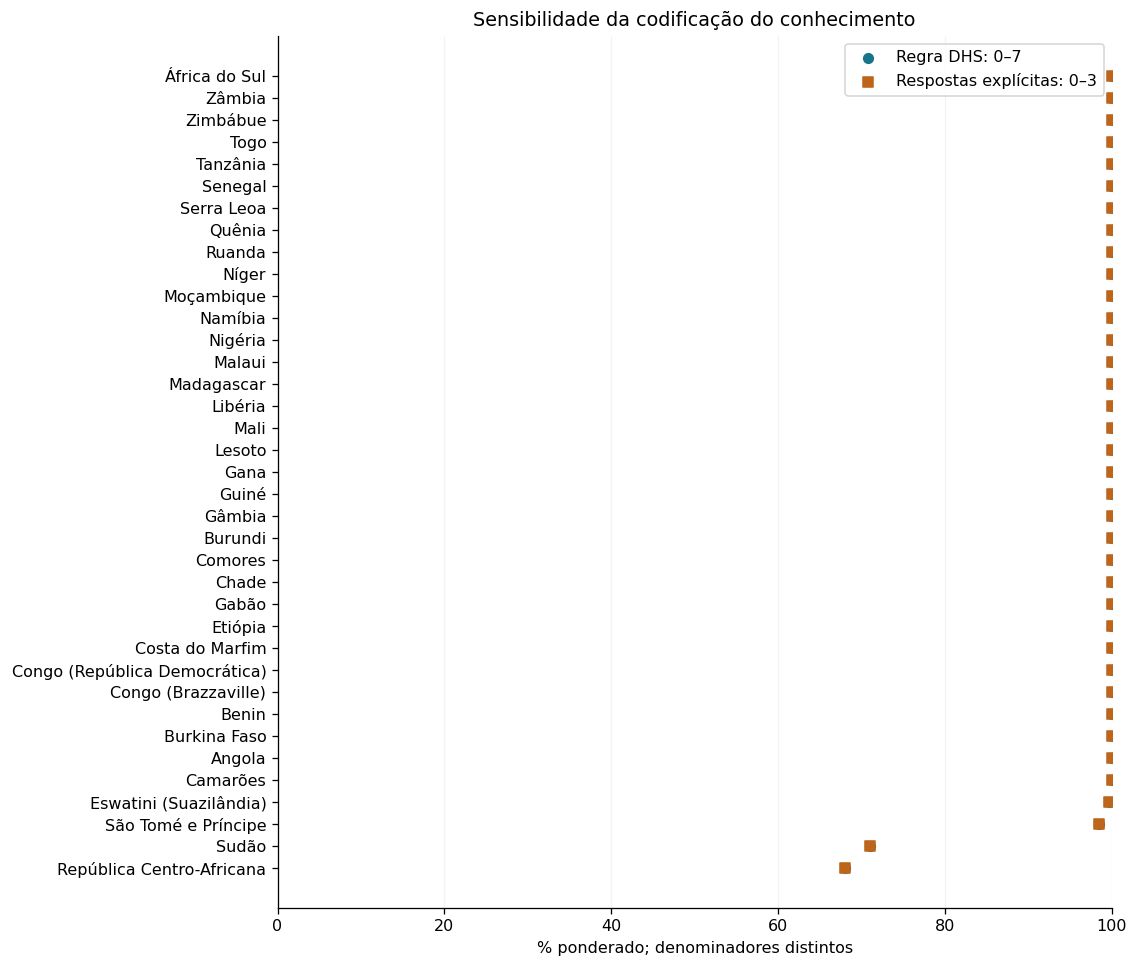

In [2]:
sql_8 = """
WITH conhecimento AS (
SELECT k.mulher_id,CASE WHEN MAX(k.nivel>0)=1 THEN 1 WHEN COUNT(*)=7 THEN 0 END AS conhece_moderno
FROM Conhecimento_Metodo k
JOIN Metodo t ON t.id=k.metodo_id
WHERE t.classe='Moderno'
GROUP BY k.mulher_id)
SELECT p.codigo,p.nome,COUNT(*) AS mulheres_respostas_validas,
ROUND(100.0*SUM(e.peso*k.conhece_moderno)/SUM(e.peso),2) AS percentual_conhece_moderno,
ROUND(100.0*SUM(e.peso*e.usa_metodo)/SUM(e.peso),2) AS percentual_uso_qualquer
FROM Entrevista e
JOIN Mulher m ON m.id=e.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id
JOIN Pais p ON p.codigo=l.pais_codigo
JOIN conhecimento k ON k.mulher_id=m.id
WHERE e.coorte!='nucleo_exclusivo'
AND e.usa_metodo IS NOT NULL
AND e.peso>0
AND k.conhece_moderno IS NOT NULL
GROUP BY p.codigo,p.nome
ORDER BY p.nome
"""
display(Markdown("```sql\n"+sql_8.strip()+"\n```"))
r8 = consulta(sql_8, amostra=False)
pares(r8.set_index('nome').rename(columns={'percentual_conhece_moderno':'Conhece moderno','percentual_uso_qualquer':'Usa algum método'}),'Conhece moderno','Usa algum método','Conhecimento e uso no mesmo denominador','% ponderado')

# Diagnóstico semântico: respostas explícitas versus códigos fora do módulo.
sql_sensibilidade_8=sql_8.replace("WHERE t.classe='Moderno'", "WHERE t.classe='Moderno' AND k.nivel BETWEEN 0 AND 3")
r8_explicito=pd.read_sql_query(sql_sensibilidade_8,conn)
detalhes(r8_explicito,'Sensibilidade Q8 · códigos 0–3 · denominador específico')
comparacao_codigos=r8[['codigo','nome','percentual_conhece_moderno']].merge(
    r8_explicito[['codigo','percentual_conhece_moderno']],on='codigo',suffixes=('_dhs','_explicito'))
pares(comparacao_codigos.set_index('nome').rename(columns={'percentual_conhece_moderno_dhs':'Regra DHS: 0–7',
    'percentual_conhece_moderno_explicito':'Respostas explícitas: 0–3'}),
    'Regra DHS: 0–7','Respostas explícitas: 0–3','Sensibilidade da codificação do conhecimento','% ponderado; denominadores distintos')


In [3]:
r8['diferenca_pp']=r8.percentual_conhece_moderno-r8.percentual_uso_qualquer
detalhes(r8[['nome','mulheres_respostas_validas','diferenca_pp']], 'Diferenças e denominadores')
display(Markdown(f"**Leitura:** conhecimento moderno e uso de qualquer método diferem em magnitude entre {len(r8)} países. O descompasso sugere investigar barreiras e preferências, mas os indicadores têm conceitos diferentes e não medem necessidade não atendida."))

display(Markdown(f"**Codificação:** {int((r8.percentual_conhece_moderno==100).sum())} países chegam a 100% pela regra 0–7. A sensibilidade usa somente respostas explícitas (0–3), em {len(r8_explicito)} países; não se deve atribuir a saturação ao acesso universal. Os denominadores diferem e o recorte de sete métodos não equivale ao indicador oficial v301."))


nome,mulheres_respostas_validas,diferenca_pp
Angola,11999,81.74
Benin,15928,85.59
Burkina Faso,17659,69.94
Burundi,17269,82.11
Camarões,13527,80.48
Chade,17719,94.65
Comores,5329,86.34
Congo (Brazzaville),10819,55.66
Congo (República Democrática),27583,83.45
Costa do Marfim,14877,77.95


**Leitura:** conhecimento moderno e uso de qualquer método diferem em magnitude entre 37 países. O descompasso sugere investigar barreiras e preferências, mas os indicadores têm conceitos diferentes e não medem necessidade não atendida.

**Codificação:** 33 países chegam a 100% pela regra 0–7. A sensibilidade usa somente respostas explícitas (0–3), em 37 países; não se deve atribuir a saturação ao acesso universal. Os denominadores diferem e o recorte de sete métodos não equivale ao indicador oficial v301.

## 6.4 Duas consultas com agregação sobre junção

### 6.4.1 Consulta 9

Agregação sobre cinco relações: uso contraceptivo por país, residência, quintil de riqueza e escolaridade. Essa tabela fornece os estratos para separar composição socioeconômica da diferença rural–urbana.

```sql
SELECT p.codigo,p.nome,d.residencia,d.riqueza,m.escolaridade,COUNT(*) AS n,
SUM(e.peso) AS peso_total,SUM(e.peso*e.usa_metodo) AS peso_uso
FROM Entrevista e
JOIN Mulher m ON m.id=e.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id
JOIN Pais p ON p.codigo=l.pais_codigo
WHERE e.coorte!='nucleo_exclusivo'
AND e.usa_metodo IS NOT NULL
AND e.peso>0
AND d.residencia IN(1,2)
AND d.riqueza BETWEEN 1
AND 5
AND m.escolaridade BETWEEN 0
AND 3
GROUP BY p.codigo,p.nome,d.residencia,d.riqueza,m.escolaridade
ORDER BY p.nome,d.residencia,d.riqueza,m.escolaridade
```

codigo,nome,residencia,riqueza,escolaridade,n,peso_total,peso_uso
AO,Angola,1,1,0,44,32.537380,0.379562
AO,Angola,1,1,1,37,34.691687,1.096992
AO,Angola,1,1,2,26,20.120082,2.879600
AO,Angola,1,2,0,284,210.090319,7.097133
AO,Angola,1,2,1,365,305.121579,15.571363
AO,Angola,1,2,2,281,233.272810,39.209519
AO,Angola,1,3,0,354,266.940714,17.497694
AO,Angola,1,3,1,813,774.803185,113.595157
AO,Angola,1,3,2,1523,1373.433466,252.920204
AO,Angola,1,3,3,23,13.033430,2.390045


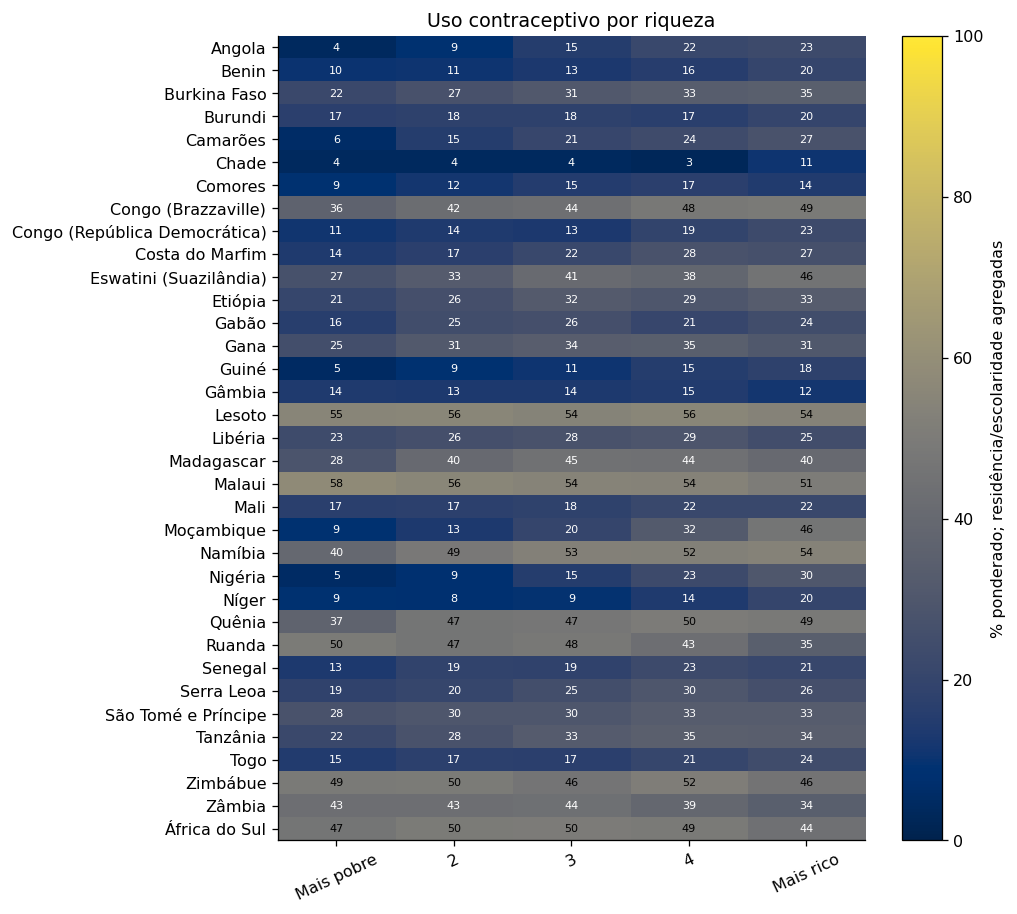

In [23]:
sql_9 = """
SELECT p.codigo,p.nome,d.residencia,d.riqueza,m.escolaridade,COUNT(*) AS n,
SUM(e.peso) AS peso_total,SUM(e.peso*e.usa_metodo) AS peso_uso
FROM Entrevista e
JOIN Mulher m ON m.id=e.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id
JOIN Pais p ON p.codigo=l.pais_codigo
WHERE e.coorte!='nucleo_exclusivo'
AND e.usa_metodo IS NOT NULL
AND e.peso>0
AND d.residencia IN(1,2)
AND d.riqueza BETWEEN 1
AND 5
AND m.escolaridade BETWEEN 0
AND 3
GROUP BY p.codigo,p.nome,d.residencia,d.riqueza,m.escolaridade
ORDER BY p.nome,d.residencia,d.riqueza,m.escolaridade
"""
display(Markdown("```sql\n"+sql_9.strip()+"\n```"))
r9 = consulta(sql_9, amostra=False)
por_riqueza=r9.groupby(['nome','riqueza'])[['peso_total','peso_uso']].sum()
por_riqueza['uso']=100*por_riqueza.peso_uso/por_riqueza.peso_total
mapa(por_riqueza.uso.unstack().rename(columns={1:'Mais pobre',5:'Mais rico'}),'Uso contraceptivo por riqueza','% ponderado; residência/escolaridade agregadas')


### 6.4.2 Consulta 10

Agregação sobre seis relações: pré-natal de quatro ou mais consultas por país, residência e riqueza. O denominador clínico considera somente o nascimento mais recente nos últimos 60 meses com resposta válida; a cobertura aparece separadamente.

```sql
SELECT p.codigo,p.nome,d.residencia,d.riqueza,COUNT(*) AS nascimentos_recentes,
SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0
AND 90 THEN 1 ELSE 0 END) AS n_validos,
SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0
AND 90 THEN e.peso ELSE 0 END) AS peso_valido,
SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 4
AND 90 THEN e.peso ELSE 0 END) AS peso_quatro_mais
FROM Entrevista e
JOIN Mulher m ON m.id=e.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id
JOIN Pais p ON p.codigo=l.pais_codigo
JOIN Nascimento n ON n.mulher_id=m.id
WHERE n.indice=1
AND e.data_cmc-n.data_cmc BETWEEN 0
AND 59
AND e.peso>0
AND d.residencia IN(1,2)
AND d.riqueza BETWEEN 1
AND 5
GROUP BY p.codigo,p.nome,d.residencia,d.riqueza
ORDER BY p.nome,d.residencia,d.riqueza
```

codigo,nome,residencia,riqueza,nascimentos_recentes,n_validos,peso_valido,peso_quatro_mais
AO,Angola,1,1,66,50,38.705283,14.212405
AO,Angola,1,2,558,425,338.977883,144.427086
AO,Angola,1,3,1537,1127,974.057613,618.625296
AO,Angola,1,4,1174,795,870.177007,702.901841
AO,Angola,1,5,873,595,710.826592,649.617429
AO,Angola,2,1,1946,1548,1229.179719,312.428171
AO,Angola,2,2,1245,993,967.351867,360.262453
AO,Angola,2,3,336,260,201.882627,116.874049
AO,Angola,2,4,60,46,36.156285,25.425303
AO,Angola,2,5,30,18,12.173921,11.714798


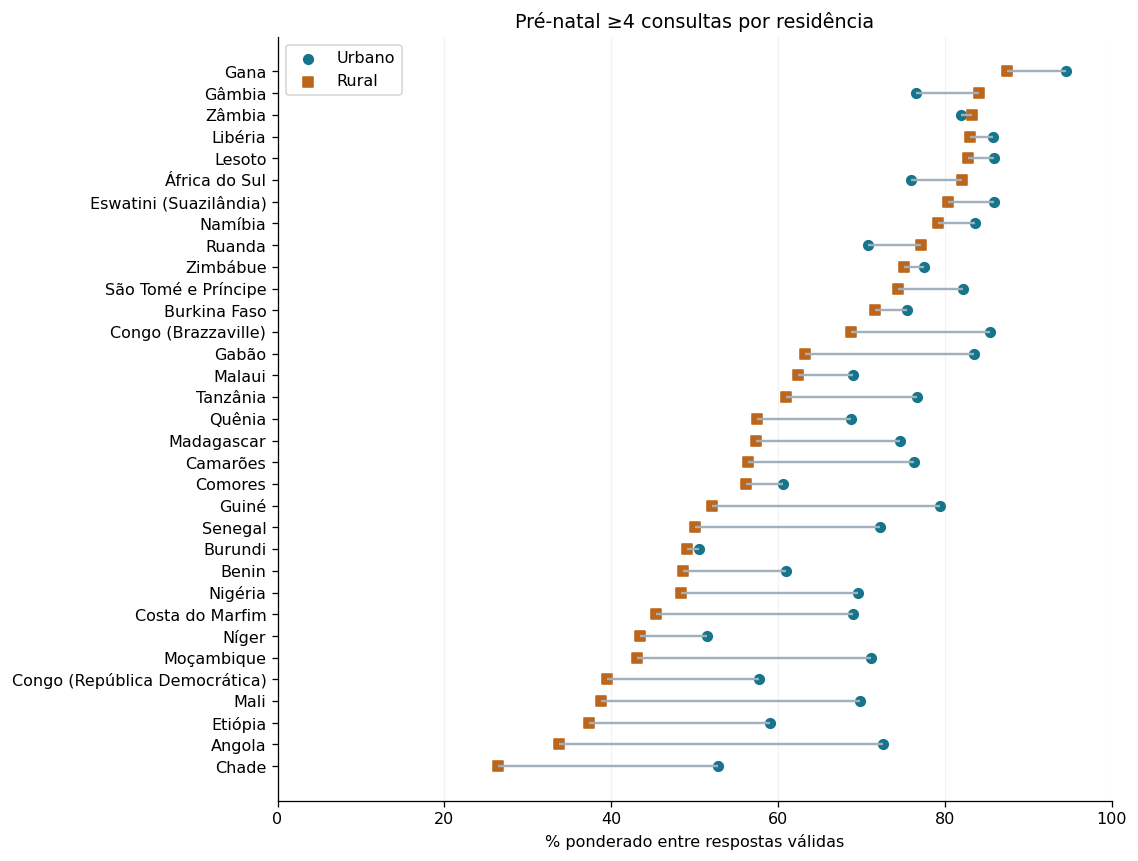

In [24]:
sql_10 = """
SELECT p.codigo,p.nome,d.residencia,d.riqueza,COUNT(*) AS nascimentos_recentes,
SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0
AND 90 THEN 1 ELSE 0 END) AS n_validos,
SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0
AND 90 THEN e.peso ELSE 0 END) AS peso_valido,
SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 4
AND 90 THEN e.peso ELSE 0 END) AS peso_quatro_mais
FROM Entrevista e
JOIN Mulher m ON m.id=e.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id
JOIN Pais p ON p.codigo=l.pais_codigo
JOIN Nascimento n ON n.mulher_id=m.id
WHERE n.indice=1
AND e.data_cmc-n.data_cmc BETWEEN 0
AND 59
AND e.peso>0
AND d.residencia IN(1,2)
AND d.riqueza BETWEEN 1
AND 5
GROUP BY p.codigo,p.nome,d.residencia,d.riqueza
ORDER BY p.nome,d.residencia,d.riqueza
"""
display(Markdown("```sql\n"+sql_10.strip()+"\n```"))
r10 = consulta(sql_10, amostra=False)
por_area=r10.groupby(['nome','residencia'])[['peso_valido','peso_quatro_mais']].sum()
por_area['prenatal']=100*por_area.peso_quatro_mais/por_area.peso_valido.replace(0,np.nan)
pares(por_area.prenatal.unstack().rename(columns={1:'Urbano',2:'Rural'}),'Urbano','Rural','Pré-natal ≥4 consultas por residência','% ponderado entre respostas válidas')


## 6.5 Cruzamentos entre países

**Contracepção:** diferença urbano − rural bruta e padronizada por riqueza × escolaridade, no mesmo suporte comum (≥30 respostas por área/estrato). O padrão é a distribuição ponderada das duas áreas dentro do país. Sensibilidade com mínimos de 50 e 100; sem significância estatística ou causalidade.

**Pré-natal:** percentual ponderado de ≥4 consultas no último nascimento dos 59 meses anteriores. Células com <30 respostas válidas ficam cinza.


codigo,pais,estratos,bruta_pp,padronizada_pp,suporte_urbano_pct,suporte_rural_pct,inversao
ST,São Tomé e Príncipe,10,-8.59,-9.73,92.96,93.38,False
MD,Madagascar,15,-2.77,-6.96,98.91,95.87,False
ZM,Zâmbia,11,-7.62,-5.58,93.60,63.76,False
KE,Quênia,17,1.86,-4.93,99.16,98.49,True
LB,Libéria,13,1.55,-4.45,82.43,98.37,True
GH,Gana,16,-0.37,-4.05,97.29,99.05,False
ET,Etiópia,11,2.00,-3.90,94.09,73.05,True
AO,Angola,10,11.47,-3.43,79.43,94.56,True
RW,Ruanda,15,-8.57,-2.89,98.84,99.20,False
CI,Costa do Marfim,14,5.86,-2.65,84.91,98.98,True


Países sem suporte comum suficiente: CF, SD


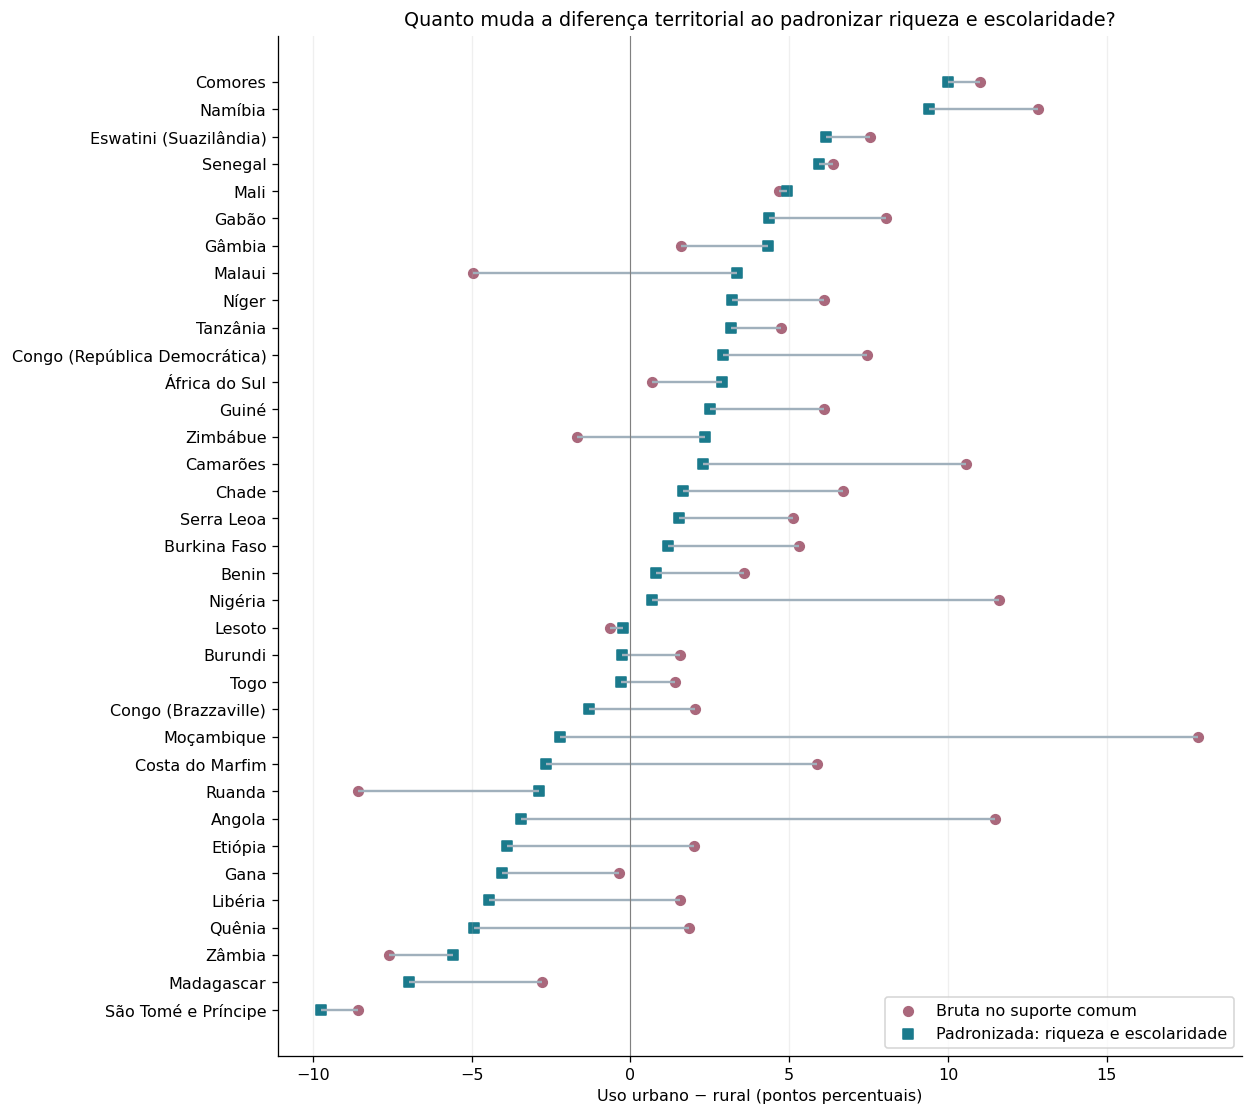

**Achado:** 35 países têm suporte comum. Em 20, o uso urbano permanece maior após padronizar riqueza e escolaridade. Houve 11 inversões de sinal entre a comparação bruta e padronizada na mesma subamostra; países: Quênia, Libéria, Etiópia, Angola, Costa do Marfim, Moçambique, Congo (Brazzaville), Togo, Burundi, Zimbábue, Malaui. As maiores mudanças em magnitude aparecem em Moçambique, Angola, Nigéria. Isso mostra por que uma média conjunta pode esconder padrões diferentes entre países.

In [25]:
ajustes=[]
for (codigo,nome),g in r9.groupby(['codigo','nome']):
    n=g.pivot(index=['riqueza','escolaridade'],columns='residencia',values='n')
    suporte=n.index[(n.get(1,0)>=30)&(n.get(2,0)>=30)]
    if len(suporte)==0: continue
    sub=g.set_index(['riqueza','escolaridade']).loc[suporte].reset_index()
    wt=sub.pivot(index=['riqueza','escolaridade'],columns='residencia',values='peso_total')
    uso=sub.pivot(index=['riqueza','escolaridade'],columns='residencia',values='peso_uso')
    padrao=(wt[1]+wt[2]); padrao=padrao/padrao.sum()
    bruto=100*(uso[1].sum()/wt[1].sum()-uso[2].sum()/wt[2].sum())
    ajustado=100*((uso[1]/wt[1]-uso[2]/wt[2])*padrao).sum()
    totais=g.groupby('residencia').peso_total.sum()
    ajustes.append([codigo,nome,len(suporte),bruto,ajustado,
                    100*wt[1].sum()/totais[1],100*wt[2].sum()/totais[2]])
ajustes=pd.DataFrame(ajustes,columns=['codigo','pais','estratos','bruta_pp','padronizada_pp','suporte_urbano_pct','suporte_rural_pct'])
ajustes['inversao']=ajustes.bruta_pp*ajustes.padronizada_pp<0
ajustes=ajustes.sort_values('padronizada_pp')
detalhes(ajustes.round(2), 'Padronização e cobertura do suporte comum')
ausentes=sorted(set(cobertura.codigo)-set(ajustes.codigo))
print('Países sem suporte comum suficiente:', ', '.join(ausentes) or 'nenhum')
fig,ax=plt.subplots(figsize=(11,max(7,len(ajustes)*.28)))
y=np.arange(len(ajustes))
ax.hlines(y,ajustes.bruta_pp,ajustes.padronizada_pp,color='#a0b0bc')
ax.scatter(ajustes.bruta_pp,y,label='Bruta no suporte comum',color='#aa687c')
ax.scatter(ajustes.padronizada_pp,y,label='Padronizada: riqueza e escolaridade',color='#1a7a8c',marker='s')
ax.set_yticks(y,ajustes.pais); ax.axvline(0,color='gray',lw=.7)
ax.set_xlabel('Uso urbano − rural (pontos percentuais)'); ax.set_title('Quanto muda a diferença territorial ao padronizar riqueza e escolaridade?')
ax.legend(loc='best'); ax.grid(axis='x',alpha=.2); fig.tight_layout(); display(fig); plt.close(fig)
inversoes=ajustes[ajustes.inversao]
maiores=ajustes.assign(mudanca=(ajustes.bruta_pp-ajustes.padronizada_pp).abs()).nlargest(3,'mudanca')
display(Markdown(f"**Achado:** {len(ajustes)} países têm suporte comum. Em {int((ajustes.padronizada_pp>0).sum())}, o uso urbano permanece maior após padronizar riqueza e escolaridade. Houve {len(inversoes)} inversões de sinal entre a comparação bruta e padronizada na mesma subamostra; " +
                ("países: "+', '.join(inversoes.pais)+'. ' if len(inversoes) else "não se demonstrou inversão de sinal. ")+ 
                "As maiores mudanças em magnitude aparecem em "+', '.join(maiores.pais)+". Isso mostra por que uma média conjunta pode esconder padrões diferentes entre países."))


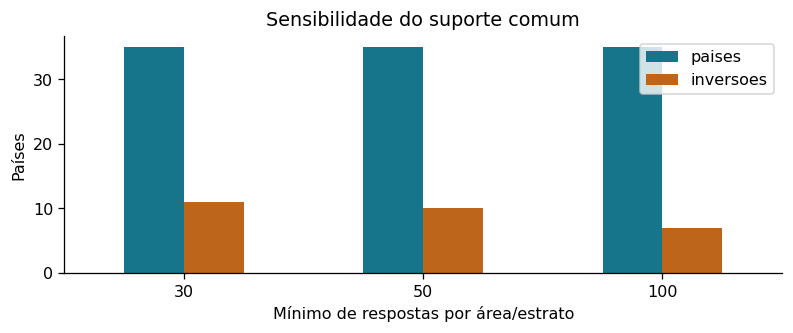

codigo,pais,minimo_por_area,estratos,bruta_pp,padronizada_pp,inversao
AO,Angola,30,10,11.47,-3.43,True
BF,Burkina Faso,30,12,5.31,1.17,False
BJ,Benin,30,15,3.57,0.80,False
BU,Burundi,30,11,1.57,-0.25,True
CD,Congo (República Democrática),30,13,7.45,2.91,False
CG,Congo (Brazzaville),30,7,2.04,-1.30,True
CI,Costa do Marfim,30,14,5.86,-2.65,True
CM,Camarões,30,11,10.56,2.28,False
ET,Etiópia,30,11,2.00,-3.90,True
GA,Gabão,30,7,8.06,4.38,False


**Robustez descritiva:** a inversão permaneceu nos três limiares em Congo (Brazzaville), Costa do Marfim, Libéria, Malaui, Moçambique, Quênia, Togo. Mudar o limiar também muda o suporte comum; esse exercício verifica sensibilidade, não significância estatística. A amostra ajustada não representa os estratos excluídos.

In [26]:
# Sensibilidade: verificar inversões com mais respostas por estrato.
sensibilidade=[]
for minimo in [30,50,100]:
    for (codigo,nome),g in r9.groupby(['codigo','nome']):
        numeros=g.pivot(index=['riqueza','escolaridade'],columns='residencia',values='n')
        suporte=numeros.index[(numeros.get(1,0)>=minimo)&(numeros.get(2,0)>=minimo)]
        if len(suporte)==0: continue
        sub=g.set_index(['riqueza','escolaridade']).loc[suporte].reset_index()
        wt=sub.pivot(index=['riqueza','escolaridade'],columns='residencia',values='peso_total')
        uso=sub.pivot(index=['riqueza','escolaridade'],columns='residencia',values='peso_uso')
        padrao=(wt[1]+wt[2]); padrao=padrao/padrao.sum()
        bruta=100*(uso[1].sum()/wt[1].sum()-uso[2].sum()/wt[2].sum())
        ajustada=100*((uso[1]/wt[1]-uso[2]/wt[2])*padrao).sum()
        sensibilidade.append([codigo,nome,minimo,len(suporte),bruta,ajustada,bruta*ajustada<0])
sensibilidade=pd.DataFrame(sensibilidade,columns=['codigo','pais','minimo_por_area','estratos','bruta_pp','padronizada_pp','inversao'])
robustez=sensibilidade.groupby('minimo_por_area').agg(paises=('codigo','nunique'),inversoes=('inversao','sum'))
fig,ax=plt.subplots(figsize=(7,3)); robustez.plot.bar(ax=ax,color=[AZUL,LARANJA],rot=0)
ax.set(xlabel='Mínimo de respostas por área/estrato',ylabel='Países',title='Sensibilidade do suporte comum'); mostrar(fig)
detalhes(sensibilidade.round(2), 'Sensibilidade por país e limiar')
persistentes=sensibilidade.groupby('pais').filter(lambda g: len(g)==3 and g.inversao.all()).pais.unique()
display(Markdown('**Robustez descritiva:** a inversão permaneceu nos três limiares em '+(', '.join(sorted(persistentes)) or 'nenhum país')+'. Mudar o limiar também muda o suporte comum; esse exercício verifica sensibilidade, não significância estatística. A amostra ajustada não representa os estratos excluídos.'))


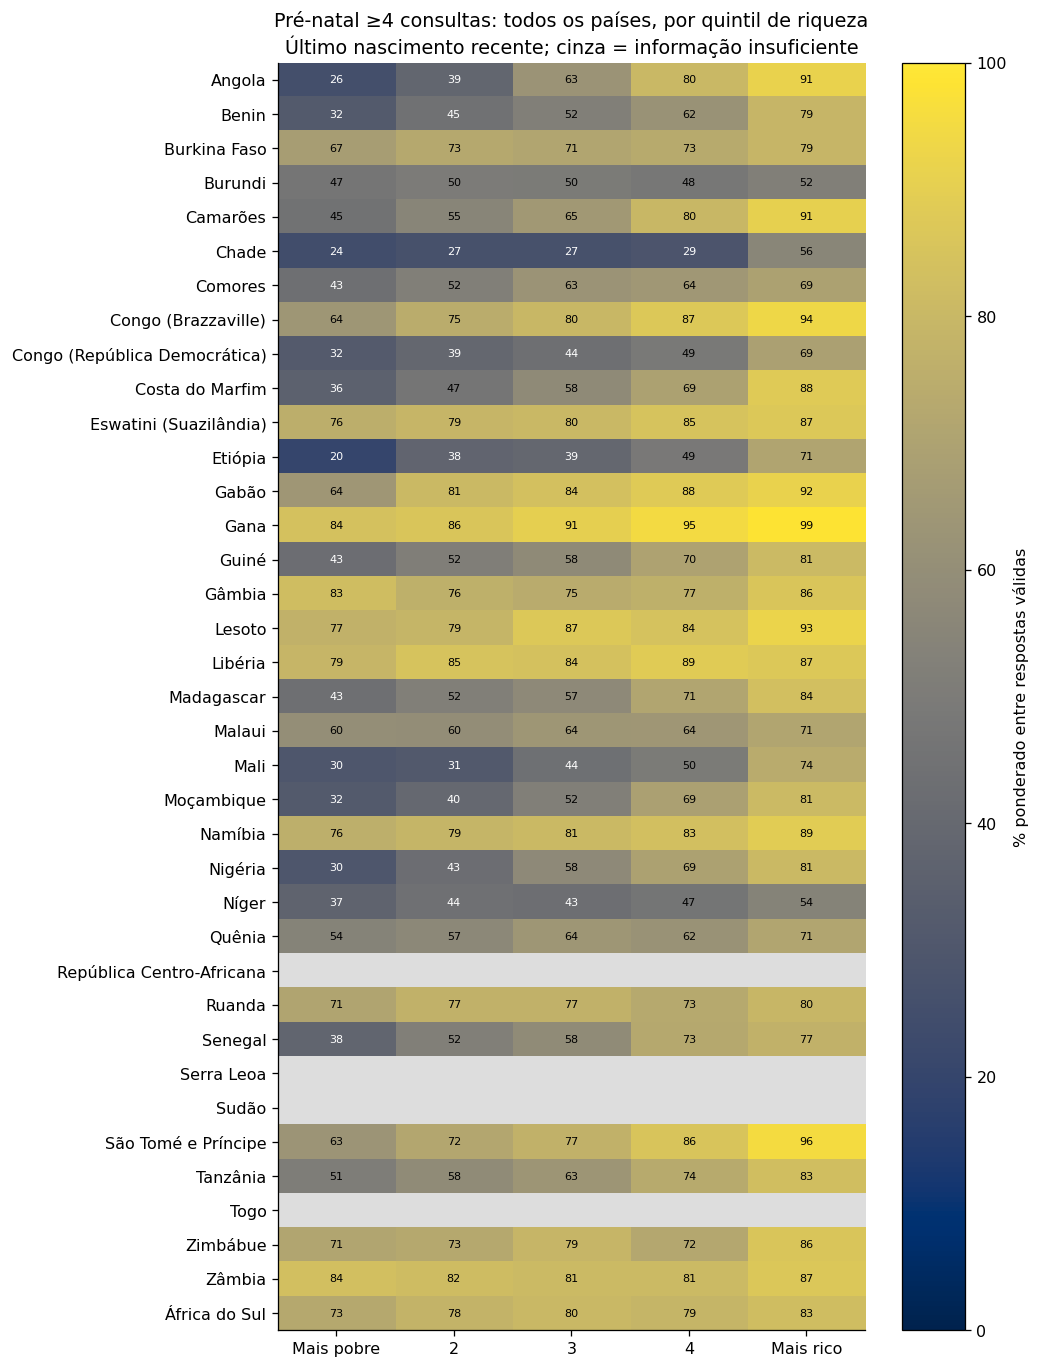

riqueza,nome,1,5,diferenca_pp
,Angola,25.76,91.47,65.71
,Benin,31.81,79.17,47.36
,Burkina Faso,67.28,79.17,11.88
,Burundi,47.07,52.18,5.11
,Camarões,45.29,90.94,45.64
,Chade,24.28,55.55,31.26
,Comores,43.42,69.46,26.04
,Congo (Brazzaville),64.05,93.71,29.66
,Congo (República Democrática),32.39,69.10,36.71
,Costa do Marfim,35.91,87.97,52.06


nome,n_validos,nascimentos_recentes,cobertura_pct
Angola,5857,7825,74.85
Benin,8750,8977,97.47
Burkina Faso,6384,9292,68.70
Burundi,8634,8639,99.94
Camarões,2324,3085,75.33
Chade,10928,11104,98.41
Comores,1730,2016,85.81
Congo (Brazzaville),6429,6463,99.47
Congo (República Democrática),12241,15064,81.26
Costa do Marfim,5657,7660,73.85


**Achado:** em 33 dos 33 países com pelo menos 30 respostas nos dois quintis extremos, o quintil mais rico apresenta maior percentual de quatro consultas. A diferença varia de 3.2 a 65.7 pontos percentuais. Países e estratos com baixa cobertura não devem ser ordenados como se o indicador tivesse a mesma completude em todos eles.

In [27]:
# Gradiente de pré-natal por país e riqueza, sem misturar pesos de países diferentes.
prenatal=r10.groupby(['codigo','nome','riqueza'],as_index=False)[['nascimentos_recentes','n_validos','peso_valido','peso_quatro_mais']].sum()
prenatal['percentual']=100*prenatal.peso_quatro_mais/prenatal.peso_valido.replace(0,np.nan)
prenatal['cobertura_pct']=100*prenatal.n_validos/prenatal.nascimentos_recentes
# Transparência: células com menos de 30 respostas não são comparadas no mapa.
prenatal.loc[prenatal.n_validos<30,'percentual']=np.nan
matriz=prenatal.pivot(index='nome',columns='riqueza',values='percentual').reindex(cobertura.nome.drop_duplicates().sort_values())
assert matriz.index.is_unique and len(matriz)==cobertura.codigo.nunique()
fig,ax=plt.subplots(figsize=(9,12))
cmap=plt.get_cmap('cividis').copy(); cmap.set_bad('#dddddd')
im=ax.imshow(matriz.to_numpy(),vmin=0,vmax=100,cmap=cmap,aspect='auto')
ax.set_yticks(np.arange(len(matriz)),matriz.index); ax.set_xticks(np.arange(5),['Mais pobre','2','3','4','Mais rico'])
for row in range(len(matriz)):
    for col in range(5):
        value=matriz.iloc[row,col]
        if pd.notna(value): ax.text(col,row,f'{value:.0f}',ha='center',va='center',fontsize=7,color='white' if value<45 else 'black')
ax.set_title('Pré-natal ≥4 consultas: todos os países, por quintil de riqueza\nÚltimo nascimento recente; cinza = informação insuficiente')
fig.colorbar(im,ax=ax,label='% ponderado entre respostas válidas'); fig.tight_layout(); display(fig); plt.close(fig)
gradiente=matriz[[1,5]].dropna().copy(); gradiente['diferenca_pp']=gradiente[5]-gradiente[1]
display(HTML('<details><summary>Gradiente entre quintis extremos</summary>'+gradiente.reset_index().round(2).to_html(index=False)+'</details>')) if 'HTML' in globals() else None
coverage=prenatal.groupby('nome')[['n_validos','nascimentos_recentes']].sum()
coverage['cobertura_pct']=100*coverage.n_validos/coverage.nascimentos_recentes
display(HTML('<details><summary>Completude do pré-natal</summary>'+coverage.reset_index().round(2).to_html(index=False)+'</details>')) if 'HTML' in globals() else None
display(Markdown(f"**Achado:** em {int((gradiente.diferenca_pp>0).sum())} dos {len(gradiente)} países com pelo menos 30 respostas nos dois quintis extremos, o quintil mais rico apresenta maior percentual de quatro consultas. A diferença varia de {gradiente.diferenca_pp.min():.1f} a {gradiente.diferenca_pp.max():.1f} pontos percentuais. Países e estratos com baixa cobertura não devem ser ordenados como se o indicador tivesse a mesma completude em todos eles."))


**Implicação social:** a composição de riqueza e escolaridade pode alterar a diferença rural–urbana. A distância entre conhecimento e uso orienta investigação de preferências e barreiras; o gradiente de pré-natal orienta investigação de acesso e completude. Esses resultados ajudam a formular prioridades, sem demonstrar qualidade clínica, autonomia ou eficácia de políticas.


## 6.6 Otimização — até 20% extra

**Índice composto de cobertura:** `Entrevista(ano, usa_metodo, mulher_id, peso)`, para uma consulta analítica que compara uso no mesmo ano. Mesma SQL e resultado antes/depois; aquecimento + sete execuções completas por condição, mediana e plano `EXPLAIN QUERY PLAN`.

O gráfico mostra o ganho medido nesta execução. Custo de criação, cache e ambiente limitam a generalização; PK/FK permanecem ativas.


```sql
SELECT p.nome,m.escolaridade,COUNT(*) AS n,SUM(e.peso) AS peso
FROM Entrevista e JOIN Mulher m ON m.id=e.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id JOIN Pais p ON p.codigo=l.pais_codigo
WHERE e.ano=? AND e.usa_metodo=1
GROUP BY p.nome,m.escolaridade ORDER BY p.nome,m.escolaridade
```

```sql
CREATE INDEX idx_entrevista_ano_uso ON Entrevista(ano,usa_metodo,mulher_id,peso);
```

id,parent,notused,detail
15,0,216,SCAN e
21,0,47,SEARCH m USING INDEX sqlite_autoindex_Mulher_1 (id=?)
27,0,46,SEARCH d USING INDEX sqlite_autoindex_Domicilio_1 (id=?)
32,0,47,SEARCH l USING INDEX sqlite_autoindex_Levantamento_1 (id=?)
37,0,47,SEARCH p USING INDEX sqlite_autoindex_Pais_1 (codigo=?)
42,0,0,USE TEMP B-TREE FOR GROUP BY


id,parent,notused,detail
15,0,55,SEARCH e USING COVERING INDEX idx_entrevista_ano_uso (ano=? AND usa_metodo=?)
22,0,47,SEARCH m USING INDEX sqlite_autoindex_Mulher_1 (id=?)
28,0,46,SEARCH d USING INDEX sqlite_autoindex_Domicilio_1 (id=?)
33,0,47,SEARCH l USING INDEX sqlite_autoindex_Levantamento_1 (id=?)
38,0,47,SEARCH p USING INDEX sqlite_autoindex_Pais_1 (codigo=?)
43,0,0,USE TEMP B-TREE FOR GROUP BY


**Plano:** SCAN e → SEARCH e USING COVERING INDEX idx_entrevista_ano_uso (ano=? AND usa_metodo=?)

execucao,antes_ms,depois_ms
1,82.2596,48.7014
2,82.8828,52.2349
3,82.3211,48.4380
4,82.6012,46.8119
5,83.3197,48.0219
6,81.4700,47.1641
7,82.3495,48.2233


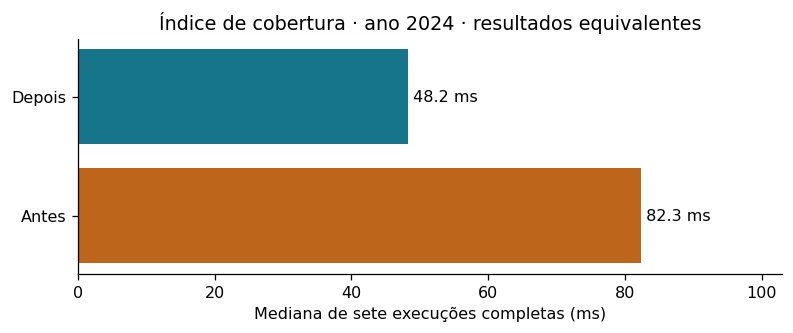

**Resultado medido:** mediana de 82.35 ms antes e 48.22 ms depois; redução de 41.4% e razão de 1.71×. Criar o índice custou 0.48 s. O índice acelera este filtro, ocupa espaço e adiciona custo à carga; o ganho não vale automaticamente para todas as dez consultas.

Banco derivado final com índice e estatísticas; resultados equivalentes confirmados.


In [28]:
conn.execute('DROP INDEX IF EXISTS idx_entrevista_ano_uso')
ano=conn.execute('SELECT ano FROM Entrevista WHERE ano IS NOT NULL GROUP BY ano ORDER BY COUNT(*) DESC LIMIT 1').fetchone()[0]
sql_otimizacao="""
SELECT p.nome,m.escolaridade,COUNT(*) AS n,SUM(e.peso) AS peso
FROM Entrevista e JOIN Mulher m ON m.id=e.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id JOIN Pais p ON p.codigo=l.pais_codigo
WHERE e.ano=? AND e.usa_metodo=1
GROUP BY p.nome,m.escolaridade ORDER BY p.nome,m.escolaridade
"""
def medir():
    esperado=conn.execute(sql_otimizacao,(ano,)).fetchall() # aquecimento
    tempos=[]
    for _ in range(7):
        t=perf_counter(); obtido=conn.execute(sql_otimizacao,(ano,)).fetchall(); tempos.append(perf_counter()-t)
        assert obtido==esperado
    return esperado,tempos
antes,tempos_antes=medir()
plano_antes=pd.read_sql_query('EXPLAIN QUERY PLAN '+sql_otimizacao,conn,params=(ano,))
t=perf_counter()
conn.execute('CREATE INDEX idx_entrevista_ano_uso ON Entrevista(ano,usa_metodo,mulher_id,peso)')
conn.commit(); custo_indice=perf_counter()-t
depois,tempos_depois=medir()
plano_depois=pd.read_sql_query('EXPLAIN QUERY PLAN '+sql_otimizacao,conn,params=(ano,))
assert antes==depois, 'A otimização deve preservar os resultados.'
assert any('idx_entrevista_ano_uso' in str(x) for x in plano_depois.detail)
display(Markdown('```sql\n'+sql_otimizacao.strip()+'\n```'))
display(Markdown('```sql\nCREATE INDEX idx_entrevista_ano_uso ON Entrevista(ano,usa_metodo,mulher_id,peso);\n```'))
detalhes(plano_antes, f'Plano antes · ano {ano}')
detalhes(plano_depois,'Plano depois')
display(Markdown('**Plano:** '+plano_antes.detail.iloc[0]+' → '+plano_depois.detail.iloc[0]))
detalhes(pd.DataFrame({'execucao':range(1,8),'antes_ms':np.array(tempos_antes)*1000,'depois_ms':np.array(tempos_depois)*1000}), 'Sete medições completas')
med_antes,med_depois=median(tempos_antes),median(tempos_depois)
ganho=100*(1-med_depois/med_antes)
fig,ax=plt.subplots(figsize=(7,3))
valores=[med_antes*1000,med_depois*1000]; ax.barh(['Antes','Depois'],valores,color=[LARANJA,AZUL])
for y,v in enumerate(valores): ax.text(v,y,f' {v:.1f} ms',va='center')
ax.set(xlim=(0,max(valores)*1.25),xlabel='Mediana de sete execuções completas (ms)',title=f'Índice de cobertura · ano {ano} · resultados equivalentes'); mostrar(fig)
display(Markdown(f"**Resultado medido:** mediana de {med_antes*1000:.2f} ms antes e {med_depois*1000:.2f} ms depois; redução de {ganho:.1f}% e razão de {med_antes/med_depois:.2f}×. Criar o índice custou {custo_indice:.2f} s. O índice acelera este filtro, ocupa espaço e adiciona custo à carga; o ganho não vale automaticamente para todas as dez consultas."))
conn.execute('ANALYZE'); conn.commit()
print('Banco derivado final com índice e estatísticas; resultados equivalentes confirmados.')


## 6.7 Requisitos e pontos extras

**Implementado:** saúde da mulher (extra) · fonte Stata reproduzível · normalização bottom-up · ≥4 entidades com ≥2 atributos próprios · ≥3 relacionamentos e M:N carregado · diagramas anexados · 10 SQL executadas · análises e gráficos · índice com plano, tempos e equivalência (até 20% extra).

**Pendente para entrega:** matrículas e autoavaliações individuais; exportação em PDF e apresentação. Exercícios/participação são pontos da disciplina e dependem das atividades externas ao notebook.


# 7. Autoavaliação dos membros

Preencher com as atividades efetivamente realizadas por cada integrante:

- **Henrique Lima Gusmão:** atividades e autoavaliação a confirmar.
- **Felipe Pires Franco:** matrícula, atividades e autoavaliação a confirmar.
- **Izabella Galdino Correia:** matrícula, atividades e autoavaliação a confirmar.
- **Alice Lina Oliveira da Silva:** matrícula, atividades e autoavaliação a confirmar.

Revisar em grupo e preparar apresentação de até seis minutos, com participação de todos.


In [29]:
assert set(cobertura.codigo)=={r[0] for r in conn.execute('SELECT codigo FROM Pais')}
for numero in range(1,11):
    tabela=globals()[f'r{numero}']
    assert len(tabela)>0, f'Consulta {numero} deve retornar dados.'
    coluna='pais_codigo' if numero<=5 else 'codigo'
    assert tabela[coluna].nunique()>1, f'Consulta {numero} deve abranger vários países.'
assert set(r3.pais_codigo)==set(cobertura.codigo)-{'SD'}, 'Sudão não possui residência disponível neste recorte.'
assert len(ajustes)>1 and len(prenatal)>1
print('Dez consultas validadas, comparação nacional de 37 países e análises ajustadas com cobertura explícita.')

assert set(panorama.codigo)==set(cobertura.codigo)
assert set(r8.codigo)==set(cobertura.codigo)
assert r9.codigo.nunique()==35


Dez consultas validadas, comparação nacional de 37 países e análises ajustadas com cobertura explícita.


In [30]:
conn.close()
assert sha256(origem)==hash_origem
print('Execução finalizada: origem preservada e banco normalizado salvo.')

Execução finalizada: origem preservada e banco normalizado salvo.
